# 07. Evaluasi dan perbandingan tiga model: K-Means, K-Medoids, DBSCAN

Bandingkan keterpisahan klaster, cakupan, ukuran kelompok, gambar hasil clustering, kestabilan, dan kesepakatan antarmodel. Peringkat model dirumuskan dari beberapa kriteria sekaligus, bukan dari satu skor.

**Mulai membaca:** [ringkasan skor tiga model](#s3) | [grafik skor](#s5) | [perbandingan per k](#s6) | [cakupan/noise](#s7) | [gambar clustering](#s8) | [diagram Silhouette](#s9) | [ARI antarmodel](#s12) | [kestabilan](#s13) | [peringkat](#s14) | [kesimpulan akademik](#s15). Grafik dan tabel tampil di bawah sel kode dan hasilnya tersimpan di notebook.

[Panduan](../00_panduan.ipynb) | [Sebelumnya](../06_kmedoids/06_kmedoids.ipynb) | [Berikutnya](../08_temporal_analysis/08_temporal_analysis.ipynb)

### Daftar bagian

- [1. Inisialisasi dan dependensi](#s1)
- [2. Kode evaluasi tiga model](#s2)
- [3. Jalankan evaluasi dan baca ringkasan perbandingan](#s3)
- [4. Bandingkan karakteristik profil](#s4)
- [5. Grafik perbandingan Silhouette, Davies-Bouldin, dan Calinski-Harabasz](#s5)
- [6. K-Means dan K-Medoids pada setiap k yang sama](#s6)
- [7. Grafik cakupan: masuk kelompok dan noise](#s7)
- [8. Gambar hasil clustering ketiga model](#s8)
- [9. Diagram Silhouette per baris dan selang bootstrap](#s9)
- [10. Grafik jumlah anggota setiap kelompok](#s10)
- [11. Grafik ciri kelompok dalam satuan asli](#s11)
- [12. Grafik kesepakatan pengelompokan dan ARI](#s12)
- [13. Kestabilan terhadap subsampel data](#s13)
- [14. Peringkat model berdasarkan banyak kriteria](#s14)
- [15. Kesimpulan evaluasi, batas hasil, dan langkah berikutnya](#s15)

**Aturan nama:** frekuensi dan magnitudo rendah/sedang/tinggi adalah peringkat relatif rata-rata kelompok di dalam model yang sama, bukan ambang seismologi. Posisi = (peringkat rata-rata - 1) / (jumlah kelompok - 1): rendah ? 1/3, sedang > 1/3 dan < 2/3, tinggi ? 2/3; nilai sama memakai peringkat rata-rata. Noise tidak diikutkan. Dengan hanya dua kelompok, rendah dan tinggi hanya menunjukkan urutan, bukan besar selisih atau signifikansi. Kategori kedalaman memakai rata-rata kelompok: dangkal < 70 km, menengah 70 sampai < 300 km, dan dalam ? 300 km; ini tidak berarti seluruh kejadian mempunyai kategori kedalaman yang sama. Nama tidak menyatakan tingkat bahaya.

<a id="s1"></a>
## 1. Inisialisasi dan dependensi

Jalankan dari atas ke bawah dengan kernel Python 3.12.11 (Seismic Research). Konfigurasi tersentral di config.json.

In [1]:
from pathlib import Path
import os
import sys

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "2")
os.environ.setdefault("OMP_NUM_THREADS", "2")
candidates = []
for parent in [Path.cwd(), *Path.cwd().parents]:
    candidates.extend([parent, parent / "seismic_research_2021_2025"])
ROOT = next((p for p in candidates if (p / "config.json").is_file() and (p / "src/common.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Buka notebook dari folder proyek seismic_research_2021_2025.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display, Image, Markdown, FileLink
from src.common import read_config
cfg = read_config(ROOT)
print("Interpreter:", sys.executable)
print("Python:", sys.version.split()[0])
print("Proyek:", ROOT)
print("Training:", cfg["train_start"], "sampai sebelum", cfg["train_end_exclusive"])
print("Testing sampai sebelum (UTC):", cfg["test_end_exclusive"])

import itertools
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score, calinski_harabasz_score
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
from src.common import ROOT, load_model, load_prepared, write_json
from src.kmedoids import KMedoids
from src.modeling import cluster_metrics
from src.preprocessing import grid_panel

Interpreter: C:\Users\yudhi\.local\bin\python3.12.exe
Python: 3.12.11
Proyek: C:\Users\yudhi\Documents\machine-learning
Training: 2021-01-01 sampai sebelum 2026-01-01
Testing sampai sebelum (UTC): 2026-10-26


<a id="s2"></a>
## 2. Kode evaluasi tiga model

Baris evaluasi pertama memakai seluruh training layak; DBSCAN menghitung metrik jarak tanpa noise. Baris kedua membatasi ketiga metode pada subset training yang ditugaskan DBSCAN. Silhouette tabel evaluasi memakai sampel tetap seed=42; tabel seleksi memakai rata-rata tiga seed. Calinski-Harabasz ditambahkan sebagai ukuran ketiga. Jika k K-Medoids berbeda dari K-Means, K-Medoids pada k yang sama ikut dievaluasi sebagai kontrol. ARI adalah kesepakatan partisi, bukan akurasi.

In [2]:
def calinski_harabasz(X, labels):
    X, labels = np.asarray(X), np.asarray(labels)
    assigned = labels >= 0
    if len(np.unique(labels[assigned])) < 2:
        return np.nan
    return float(calinski_harabasz_score(X[assigned], labels[assigned]))

def evaluate(root=ROOT):
    root = Path(root)
    cfg, _, train, X, _, _ = load_prepared(root)
    km, _ = load_model(root, "kmeans")
    kd, _ = load_model(root, "kmedoids")
    db, dbmeta = load_model(root, "dbscan")
    models = [("kmeans", km.labels_), ("kmedoids", kd.labels_), ("dbscan", db.labels_)]
    matched_path = root / "models/kmedoids/model_matched_k.joblib"
    if matched_path.exists():
        matched = joblib.load(matched_path)
        if matched.n_clusters != kd.n_clusters:
            models.append(("kmedoids_matched_k", matched.labels_))
    rows = []
    for method, labels in models:
        rows.append({"model": method, "evaluation_scope": "seluruh baris training layak; noise dikeluarkan dari metrik jarak",
                     **cluster_metrics(X, labels, cfg["silhouette_sample_size"]), "calinski_harabasz": calinski_harabasz(X, labels)})
    common = db.labels_ >= 0
    for method, labels in models:
        if common.any():
            rows.append({"model": method, "evaluation_scope": "subset identik: baris training yang ditugaskan DBSCAN",
                         **cluster_metrics(X[common], labels[common], cfg["silhouette_sample_size"]),
                         "calinski_harabasz": calinski_harabasz(X[common], labels[common])})
    scores = pd.DataFrame(rows)
    scores["dbscan_diagnostic_only"] = dbmeta["diagnostic_only"]
    scores.to_csv(root / "reports/evaluation/model_comparison.csv", index=False)
    ari = adjusted_rand_score(km.labels_[common], db.labels_[common]) if common.sum() > 1 else None
    pairwise = {}
    for (name_a, labels_a), (name_b, labels_b) in itertools.combinations(models, 2):
        pairwise[f"{name_a}_vs_{name_b}"] = {
            "ari_all_rows": float(adjusted_rand_score(labels_a, labels_b)),
            "ari_common_assigned": float(adjusted_rand_score(labels_a[common], labels_b[common])) if common.sum() > 1 else None}
    write_json(root / "reports/evaluation/agreement.json", {"ari_common_assigned": ari, "pairwise_ari": pairwise,
               "n_common_assigned": int(common.sum()), "fraction_common_assigned": float(common.mean()),
               "meaning": "kesepakatan partisi, bukan akurasi terhadap ground truth"})
    return scores

def subsample_stability(root=ROOT, fraction=.8):
    """Fit ulang tiap model pada subsampel acak, lalu bandingkan dengan label referensi pada baris subsampel yang sama."""
    root = Path(root)
    cfg, _, _, X, _, _ = load_prepared(root)
    km, _ = load_model(root, "kmeans")
    kd, _ = load_model(root, "kmedoids")
    db, _ = load_model(root, "dbscan")
    reference = {"kmeans": km.labels_, "kmedoids": kd.labels_, "dbscan": db.labels_}

    def refit(method, seed):
        if method == "kmeans":
            return KMeans(n_clusters=km.n_clusters, n_init=20, random_state=seed)
        if method == "kmedoids":
            return KMedoids(n_clusters=kd.n_clusters, random_state=seed)
        return DBSCAN(eps=db.eps, min_samples=db.min_samples, n_jobs=1)

    rows = []
    with threadpool_limits(limits=2):
        for seed in cfg["stability_seeds"]:
            subset = np.sort(np.random.default_rng(seed).choice(len(X), int(fraction * len(X)), replace=False))
            for method, labels in reference.items():
                alternate = refit(method, seed).fit_predict(X[subset])
                base = labels[subset]
                both = (base >= 0) & (alternate >= 0)
                rows.append({"method": method, "seed": seed, "n_rows": len(subset),
                             "ari_including_noise": adjusted_rand_score(base, alternate),
                             "ari_common_assigned": adjusted_rand_score(base[both], alternate[both]) if both.sum() > 1 else np.nan,
                             "common_assigned_fraction": float(both.mean()), "n_clusters": len(set(alternate.tolist()) - {-1})})
    result = pd.DataFrame(rows)
    result.to_csv(root / "reports/evaluation/subsample_stability.csv", index=False)
    return result

<a id="s3"></a>
## 3. Jalankan evaluasi dan baca ringkasan perbandingan

Mulai membaca hasil di sini. Skor utama memakai baris yang sama untuk ketiga model. Noise dan cakupan pada seluruh training dibaca terpisah agar tidak tertukar dengan akurasi.

In [3]:
comparison = evaluate(ROOT)
evaluation_cfg, evaluation_panel, evaluation_train, evaluation_X, _, _ = load_prepared(ROOT)
km_model, km_metadata = load_model(ROOT, "kmeans")
kd_model, kd_metadata = load_model(ROOT, "kmedoids")
db_model, db_metadata = load_model(ROOT, "dbscan")
assert len(km_model.labels_) == len(kd_model.labels_) == len(db_model.labels_) == len(evaluation_train)
model_labels = {"kmeans": km_model.labels_, "kmedoids": kd_model.labels_, "dbscan": db_model.labels_}
has_control = "kmedoids_matched_k" in set(comparison["model"])
if has_control:
    model_labels["kmedoids_matched_k"] = joblib.load(ROOT / "models/kmedoids/model_matched_k.joblib").labels_
model_order = list(model_labels)
main_models = ["kmeans", "kmedoids", "dbscan"]
db_clusters = len(set(db_model.labels_.tolist()) - {-1})
model_names = {"kmeans": f"K-Means (k={km_model.n_clusters})", "kmedoids": f"K-Medoids (k={kd_model.n_clusters})",
               "dbscan": f"DBSCAN ({db_clusters} kelompok)", "kmedoids_matched_k": f"K-Medoids (k={km_model.n_clusters}, kontrol)"}
model_colors = {"kmeans": "#0072B2", "kmedoids": "#009E73", "dbscan": "#B44A00", "kmedoids_matched_k": "#7BC8A4"}
whole = comparison.loc[comparison["evaluation_scope"].str.startswith("seluruh")].set_index("model").loc[model_order]
fair = comparison.loc[comparison["evaluation_scope"].str.startswith("subset identik")].set_index("model").loc[model_order]
common = db_model.labels_ >= 0
assert fair["n_rows"].eq(common.sum()).all()
assert fair["n_assigned"].eq(common.sum()).all()
jumlah = lambda value: f"{int(value):,}".replace(",", ".")
angka = lambda value, digits=4: f"{value:.{digits}f}".replace(".", ",")
display(Markdown(f"""### Apa yang dibandingkan?

Tiga algoritma pengelompokan dibandingkan pada **data, fitur, dan ukuran jarak yang sama**:
K-Means (pusat berupa rata-rata), K-Medoids/PAM (pusat berupa observasi nyata), dan DBSCAN (kelompok berbasis kepadatan).

- Ketiganya dibentuk dari **{jumlah(len(evaluation_train))} baris training 2021-2025** dan lima fitur standar yang sama.
  Satu baris berarti satu kotak selama satu triwulan, bukan satu kejadian gempa.
- K-Means dan K-Medoids menugaskan seluruh baris. DBSCAN dapat menyisakan noise.
- Skor dibandingkan pada **{jumlah(common.sum())} baris yang sama**, yaitu baris yang masuk kelompok DBSCAN.
  Label tetap hasil training semula; tidak ada pelatihan ulang pada subset ini.
- Jumlah kelompok dipilih masing-masing algoritma dengan aturan yang sama (Silhouette tertinggi, lalu DBI terendah).
  K-Means memilih k={km_model.n_clusters}, K-Medoids memilih k={kd_model.n_clusters}, DBSCAN menghasilkan {db_clusters} kelompok.
  Karena Silhouette cenderung menguntungkan k kecil, tabel juga memuat **K-Medoids pada k yang sama dengan K-Means** sebagai kontrol,
  dan bagian 6 membandingkan kedua algoritma pada setiap k.
- Data 2026 tidak digunakan di sini; hasil pengujiannya ada di notebook 10.

### Ringkasan skor pada baris yang sama
"""))
summary_table = pd.DataFrame({
    "Model": [model_names[key] for key in model_order],
    "Silhouette (makin tinggi makin baik)": fair["silhouette"].to_numpy(),
    "Davies-Bouldin (makin rendah makin baik)": fair["davies_bouldin"].to_numpy(),
    "Calinski-Harabasz (makin tinggi makin baik)": fair["calinski_harabasz"].to_numpy(),
    "Jumlah kelompok": fair["n_clusters"].to_numpy(),
    "Kelompok terkecil (baris)": fair["smallest_cluster_size"].to_numpy(),
    "Kelompok terbesar (%)": (fair["largest_cluster_fraction_assigned"] * 100).to_numpy(),
}).round(4)
display(summary_table)
km_search = pd.read_csv(ROOT / "models/kmeans/parameter_search.csv").set_index("k")
kd_search = pd.read_csv(ROOT / "models/kmedoids/parameter_search.csv").set_index("k")
silhouette_sd = max(km_search.loc[km_model.n_clusters, "silhouette_std"], kd_search.loc[kd_model.n_clusters, "silhouette_std"])
silhouette_sorted = fair.loc[main_models, "silhouette"].sort_values(ascending=False)
best_silhouette = silhouette_sorted.index[0]
silhouette_gap = silhouette_sorted.iloc[0] - silhouette_sorted.iloc[1]
silhouette_note = (f"selisih dengan peringkat kedua ({angka(silhouette_gap, 4)}) lebih kecil dari simpangan baku antarsampel Silhouette ({angka(silhouette_sd, 4)}), sehingga keduanya dianggap seri"
                   if silhouette_gap < silhouette_sd else f"selisih dengan peringkat kedua {angka(silhouette_gap, 4)}")
best_dbi = fair.loc[main_models, "davies_bouldin"].idxmin()
best_ch = fair.loc[main_models, "calinski_harabasz"].idxmax()
display(Markdown(f"""**Cara membaca hasil:** di antara tiga model utama, Silhouette tertinggi dimiliki **{model_names[best_silhouette]}** ({silhouette_note}),
DBI terendah dimiliki **{model_names[best_dbi]}**, dan Calinski-Harabasz tertinggi dimiliki **{model_names[best_ch]}**.
Ketiganya adalah ukuran internal tentang keterpisahan dan kekompakan, bukan akurasi prediksi gempa.
Silhouette memakai sampel tetap maksimal {jumlah(evaluation_cfg['silhouette_sample_size'])} baris (seed 42);
DBI dan Calinski-Harabasz memakai seluruh baris yang dibandingkan. Noise tidak dimasukkan ke skor jarak DBSCAN.
"""))


### Apa yang dibandingkan?

Tiga algoritma pengelompokan dibandingkan pada **data, fitur, dan ukuran jarak yang sama**:
K-Means (pusat berupa rata-rata), K-Medoids/PAM (pusat berupa observasi nyata), dan DBSCAN (kelompok berbasis kepadatan).

- Ketiganya dibentuk dari **13.471 baris training 2021-2025** dan lima fitur standar yang sama.
  Satu baris berarti satu kotak selama satu triwulan, bukan satu kejadian gempa.
- K-Means dan K-Medoids menugaskan seluruh baris. DBSCAN dapat menyisakan noise.
- Skor dibandingkan pada **12.253 baris yang sama**, yaitu baris yang masuk kelompok DBSCAN.
  Label tetap hasil training semula; tidak ada pelatihan ulang pada subset ini.
- Jumlah kelompok dipilih masing-masing algoritma dengan aturan yang sama (Silhouette tertinggi, lalu DBI terendah).
  K-Means memilih k=6, K-Medoids memilih k=2, DBSCAN menghasilkan 7 kelompok.
  Karena Silhouette cenderung menguntungkan k kecil, tabel juga memuat **K-Medoids pada k yang sama dengan K-Means** sebagai kontrol,
  dan bagian 6 membandingkan kedua algoritma pada setiap k.
- Data 2026 tidak digunakan di sini; hasil pengujiannya ada di notebook 10.

### Ringkasan skor pada baris yang sama


,Model,Silhouette (makin tinggi makin baik),Davies-Bouldin (makin rendah makin baik),Calinski-Harabasz (makin tinggi makin baik),Jumlah kelompok,Kelompok terkecil (baris),Kelompok terbesar (%)
0,K-Means (k=6),0.4257,0.8665,7441.8936,6,352,45.0257
1,K-Medoids (k=2),0.4298,1.1103,6007.1899,2,2559,79.1153
2,DBSCAN (7 kelompok),0.1261,2.0116,1776.2069,7,28,39.6638
3,"K-Medoids (k=6, kontrol)",0.3472,1.0078,7261.1127,6,1033,26.7037


**Cara membaca hasil:** di antara tiga model utama, Silhouette tertinggi dimiliki **K-Medoids (k=2)** (selisih dengan peringkat kedua (0,0041) lebih kecil dari simpangan baku antarsampel Silhouette (0,0108), sehingga keduanya dianggap seri),
DBI terendah dimiliki **K-Means (k=6)**, dan Calinski-Harabasz tertinggi dimiliki **K-Means (k=6)**.
Ketiganya adalah ukuran internal tentang keterpisahan dan kekompakan, bukan akurasi prediksi gempa.
Silhouette memakai sampel tetap maksimal 2.000 baris (seed 42);
DBI dan Calinski-Harabasz memakai seluruh baris yang dibandingkan. Noise tidak dimasukkan ke skor jarak DBSCAN.


<a id="s4"></a>
## 4. Bandingkan karakteristik profil

Nama deskriptif disusun setelah clustering pada notebook 04, 05, dan 06. Tabel di sini memakai aturan nama yang sama. Kelompok A pada satu metode tidak sama dengan Kelompok A metode lain.

**Aturan nama:** frekuensi dan magnitudo rendah/sedang/tinggi adalah peringkat relatif rata-rata kelompok di dalam model yang sama, bukan ambang seismologi. Posisi = (peringkat rata-rata - 1) / (jumlah kelompok - 1): rendah ? 1/3, sedang > 1/3 dan < 2/3, tinggi ? 2/3; nilai sama memakai peringkat rata-rata. Noise tidak diikutkan. Dengan hanya dua kelompok, rendah dan tinggi hanya menunjukkan urutan, bukan besar selisih atau signifikansi. Kategori kedalaman memakai rata-rata kelompok: dangkal < 70 km, menengah 70 sampai < 300 km, dan dalam ? 300 km; ini tidak berarti seluruh kejadian mempunyai kategori kedalaman yang sama. Nama tidak menyatakan tingkat bahaya.

In [4]:
from src.mapping import profile_interpretation_table
for method, title in [("kmeans", "K-Means"), ("kmedoids", "K-Medoids"), ("dbscan", "DBSCAN")]:
    display(Markdown(f"### Kelompok {title}"))
    with pd.option_context("display.max_colwidth", None):
        display(profile_interpretation_table(ROOT, method, cfg))
if has_control:
    display(Markdown(f"### Kelompok K-Medoids k={km_model.n_clusters} (kontrol jumlah kelompok)"))
    control_path = ROOT / "models/kmedoids/profiles_matched_k.csv"
    with pd.option_context("display.max_colwidth", None):
        display(profile_interpretation_table(ROOT, "kmedoids", cfg, control_path))
    display(Markdown("Nama deskriptif dibuat setelah clustering dari rata-rata training. Huruf kelompok kontrol tidak setara dengan huruf pada model k=2 atau K-Means."))


### Kelompok K-Means

,Kode algoritma,Nama untuk menjelaskan hasil,Gempa per kotak per triwulan (rata-rata),Magnitudo (rata-rata),Kedalaman km (rata-rata),Jumlah kotak-periode pembentuk kelompok
0,KMEANS_P0,"Kelompok A: Profil kedalaman rata-rata dangkal, frekuensi relatif sedang, magnitudo relatif sedang",1.69,4.21,23.28,2895
1,KMEANS_P1,"Kelompok B: Profil kedalaman rata-rata dalam, frekuensi relatif rendah, magnitudo relatif tinggi",1.22,4.24,467.64,536
2,KMEANS_P2,"Kelompok C: Profil kedalaman rata-rata menengah, frekuensi relatif rendah, magnitudo relatif rendah",1.65,3.41,137.88,1348
3,KMEANS_P3,"Kelompok D: Profil kedalaman rata-rata menengah, frekuensi relatif tinggi, magnitudo relatif tinggi",2.41,4.23,145.44,1407
4,KMEANS_P4,"Kelompok E: Profil kedalaman rata-rata dangkal, frekuensi relatif sedang, magnitudo relatif rendah",1.68,3.35,19.59,5528
5,KMEANS_P5,"Kelompok F: Profil kedalaman rata-rata dangkal, frekuensi relatif tinggi, magnitudo relatif sedang",8.93,3.67,38.30,1757


### Kelompok K-Medoids

,Kode algoritma,Nama untuk menjelaskan hasil,Gempa per kotak per triwulan (rata-rata),Magnitudo (rata-rata),Kedalaman km (rata-rata),Jumlah kotak-periode pembentuk kelompok
0,KMEDOIDS_P0,"Kelompok A: Profil kedalaman rata-rata dangkal, frekuensi relatif tinggi, magnitudo relatif rendah",2.79,3.64,23.15,10086
1,KMEDOIDS_P1,"Kelompok B: Profil kedalaman rata-rata menengah, frekuensi relatif rendah, magnitudo relatif tinggi",2.37,3.93,192.20,3385


### Kelompok DBSCAN

,Kode algoritma,Nama untuk menjelaskan hasil,Gempa per kotak per triwulan (rata-rata),Magnitudo (rata-rata),Kedalaman km (rata-rata),Jumlah kotak-periode pembentuk kelompok
0,DBSCAN_P0,"Kelompok A: Profil kedalaman rata-rata dangkal, frekuensi relatif rendah, magnitudo relatif rendah",1.00,3.66,18.53,4860
1,DBSCAN_P1,"Kelompok B: Profil kedalaman rata-rata menengah, frekuensi relatif tinggi, magnitudo relatif tinggi",2.91,3.93,144.34,459
2,DBSCAN_P2,"Kelompok C: Profil kedalaman rata-rata menengah, frekuensi relatif rendah, magnitudo relatif tinggi",1.00,3.88,208.79,1730
3,DBSCAN_P3,"Kelompok D: Profil kedalaman rata-rata dangkal, frekuensi relatif tinggi, magnitudo relatif rendah",3.70,3.61,23.42,4538
4,DBSCAN_P4,"Kelompok E: Profil kedalaman rata-rata menengah, frekuensi relatif sedang, magnitudo relatif sedang",2.00,3.69,74.99,467
5,DBSCAN_P5,"Kelompok F: Profil kedalaman rata-rata menengah, frekuensi relatif tinggi, magnitudo relatif rendah",3.32,3.63,95.03,171
6,DBSCAN_P6,"Kelompok G: Profil kedalaman rata-rata menengah, frekuensi relatif sedang, magnitudo relatif tinggi",2.00,4.17,285.08,28
7,NOISE,Tidak masuk kelompok historis DBSCAN,8.09,3.97,165.10,1218


### Kelompok K-Medoids k=6 (kontrol jumlah kelompok)

Kode algoritma,Nama untuk menjelaskan hasil,Gempa per kotak per triwulan (rata-rata),Magnitudo (rata-rata),Kedalaman km (rata-rata),Jumlah kotak-periode pembentuk kelompok
KMEDOIDS_MATCHED_K_P0,"Kelompok A: Profil kedalaman rata-rata dangkal, frekuensi relatif tinggi, magnitudo relatif sedang (2,21 kejadian/kotak-triwulan)",2.21,3.59,23.63,3300
KMEDOIDS_MATCHED_K_P1,"Kelompok B: Profil kedalaman rata-rata menengah, frekuensi relatif sedang, magnitudo relatif tinggi",2.00,4.25,240.12,1823
KMEDOIDS_MATCHED_K_P2,"Kelompok C: Profil kedalaman rata-rata dangkal, frekuensi relatif rendah, magnitudo relatif rendah",1.27,3.21,18.97,3088
KMEDOIDS_MATCHED_K_P3,"Kelompok D: Profil kedalaman rata-rata menengah, frekuensi relatif sedang, magnitudo relatif rendah",1.48,3.38,152.74,1163
KMEDOIDS_MATCHED_K_P4,"Kelompok E: Profil kedalaman rata-rata dangkal, frekuensi relatif tinggi, magnitudo relatif sedang (8,15 kejadian/kotak-triwulan)",8.15,3.72,40.61,2055
KMEDOIDS_MATCHED_K_P5,"Kelompok F: Profil kedalaman rata-rata dangkal, frekuensi relatif rendah, magnitudo relatif tinggi",1.38,4.36,23.86,2042


Nama dibuat setelah clustering dari rata-rata training. Huruf kelompok kontrol tidak setara dengan huruf pada model k=2 atau K-Means.

<a id="s5"></a>
## 5. Grafik perbandingan Silhouette, Davies-Bouldin, dan Calinski-Harabasz

Grafik ini memakai subset identik, yaitu baris training yang ditugaskan DBSCAN. Setiap ukuran punya sumbu dan arah penilaian sendiri.

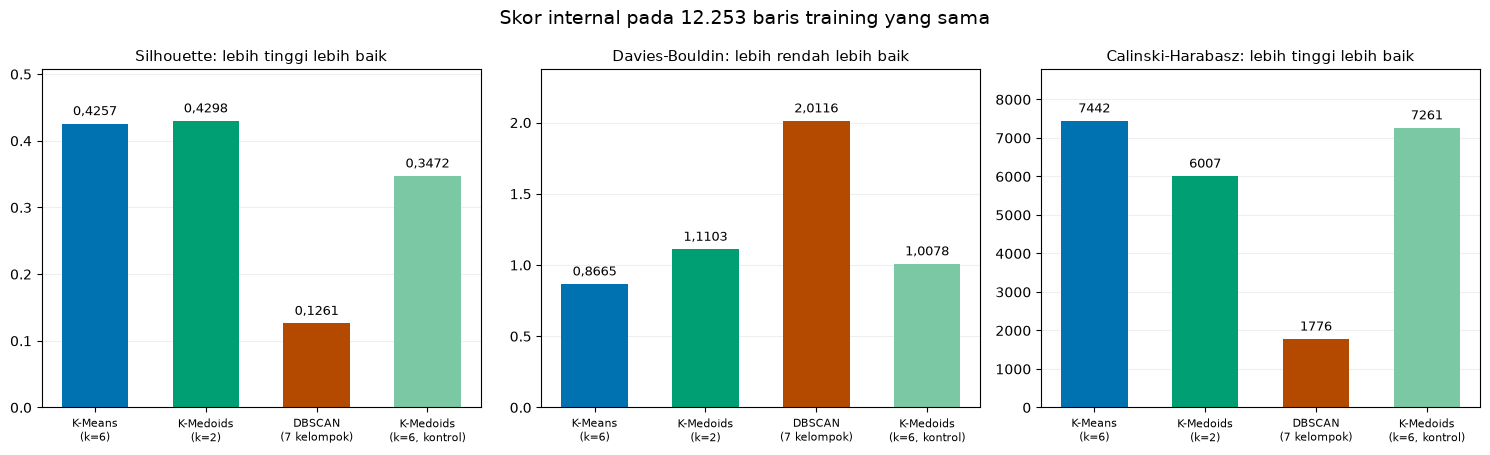

**Cara membaca:** bandingkan batang pada panel yang sama. Sumbu setiap panel berbeda karena satuan dan arah penilaian berbeda. Batang paling kanan, jika ada, adalah K-Medoids dengan jumlah kelompok yang sama seperti K-Means sehingga pengaruh algoritma dapat dipisahkan dari pengaruh jumlah kelompok.

### Angka lengkap untuk dua cakupan evaluasi

,Model,Cakupan,Baris masukan,Baris masuk kelompok,Kelompok,Silhouette,DBI,Calinski-Harabasz
0,K-Means (k=6),Seluruh training; skor DBSCAN hanya pada anggo...,13471,13471,6,0.3987,0.9328,7031.2536
1,K-Medoids (k=2),Seluruh training; skor DBSCAN hanya pada anggo...,13471,13471,2,0.4064,1.2481,5791.5249
2,DBSCAN (7 kelompok),Seluruh training; skor DBSCAN hanya pada anggo...,13471,12253,7,0.1261,2.0116,1776.2069
3,"K-Medoids (k=6, kontrol)",Seluruh training; skor DBSCAN hanya pada anggo...,13471,13471,6,0.3102,1.0459,6160.1042
4,K-Means (k=6),Subset identik; semua model pada baris yang sama,12253,12253,6,0.4257,0.8665,7441.8936
5,K-Medoids (k=2),Subset identik; semua model pada baris yang sama,12253,12253,2,0.4298,1.1103,6007.1899
6,DBSCAN (7 kelompok),Subset identik; semua model pada baris yang sama,12253,12253,7,0.1261,2.0116,1776.2069
7,"K-Medoids (k=6, kontrol)",Subset identik; semua model pada baris yang sama,12253,12253,6,0.3472,1.0078,7261.1127


Silhouette pada seluruh training dapat berbeda dari subset identik karena baris yang dinilai berbeda. Skor seleksi pada notebook 04, 05, dan 06 memakai rata-rata tiga sampel, sedangkan evaluasi ini memakai satu sampel tetap. Tidak ada model yang dilatih ulang di bagian ini.

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
panels = [("silhouette", "Silhouette: lebih tinggi lebih baik", 4), ("davies_bouldin", "Davies-Bouldin: lebih rendah lebih baik", 4),
          ("calinski_harabasz", "Calinski-Harabasz: lebih tinggi lebih baik", 0)]
for ax, (metric, title, digits) in zip(axes, panels):
    values = fair[metric].to_numpy()
    bars = ax.bar(range(len(model_order)), values, color=[model_colors[key] for key in model_order], width=.6)
    ax.bar_label(bars, labels=[angka(value, digits) for value in values], padding=4, fontsize=9)
    ax.set_xticks(range(len(model_order)), [model_names[key].replace(" (", chr(10) + "(") for key in model_order], fontsize=8)
    ax.set_title(title, fontsize=11)
    ax.grid(axis="y", alpha=.2)
    ax.set_axisbelow(True)
    low, high = min(0, values.min()), values.max()
    ax.set_ylim(low * 1.2 if low < 0 else 0, high * 1.18)
fig.suptitle(f"Skor internal pada {jumlah(common.sum())} baris training yang sama", fontsize=14)
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/evaluation_scores_common_subset.png", dpi=160)
plt.show()
plt.close(fig)
display(Markdown("**Cara membaca:** bandingkan batang pada panel yang sama. Sumbu setiap panel berbeda karena satuan dan arah penilaian berbeda. Batang paling kanan, jika ada, adalah K-Medoids dengan jumlah kelompok yang sama seperti K-Means sehingga pengaruh algoritma dapat dipisahkan dari pengaruh jumlah kelompok."))
display(Markdown("### Angka lengkap untuk dua cakupan evaluasi"))
details = comparison[["model", "evaluation_scope", "n_rows", "n_assigned", "n_clusters", "silhouette", "davies_bouldin", "calinski_harabasz"]].copy()
details["model"] = details["model"].map(model_names)
details["evaluation_scope"] = details["evaluation_scope"].map(lambda text: "Subset identik; semua model pada baris yang sama" if text.startswith("subset identik") else "Seluruh training; skor DBSCAN hanya pada anggota kelompok")
display(details.rename(columns={"model": "Model", "evaluation_scope": "Cakupan", "n_rows": "Baris masukan", "n_assigned": "Baris masuk kelompok", "n_clusters": "Kelompok",
                                "silhouette": "Silhouette", "davies_bouldin": "DBI", "calinski_harabasz": "Calinski-Harabasz"}).round(4))
display(Markdown("Silhouette pada seluruh training dapat berbeda dari subset identik karena baris yang dinilai berbeda. Skor seleksi pada notebook 04, 05, dan 06 memakai rata-rata tiga sampel, sedangkan evaluasi ini memakai satu sampel tetap. Tidak ada model yang dilatih ulang di bagian ini."))


<a id="s6"></a>
## 6. K-Means dan K-Medoids pada setiap k yang sama

Silhouette dan DBI bergantung pada jumlah kelompok. Bagian ini membandingkan K-Means dan K-Medoids pada k=2..8 agar pengaruh algoritma terpisah dari pengaruh pemilihan k.

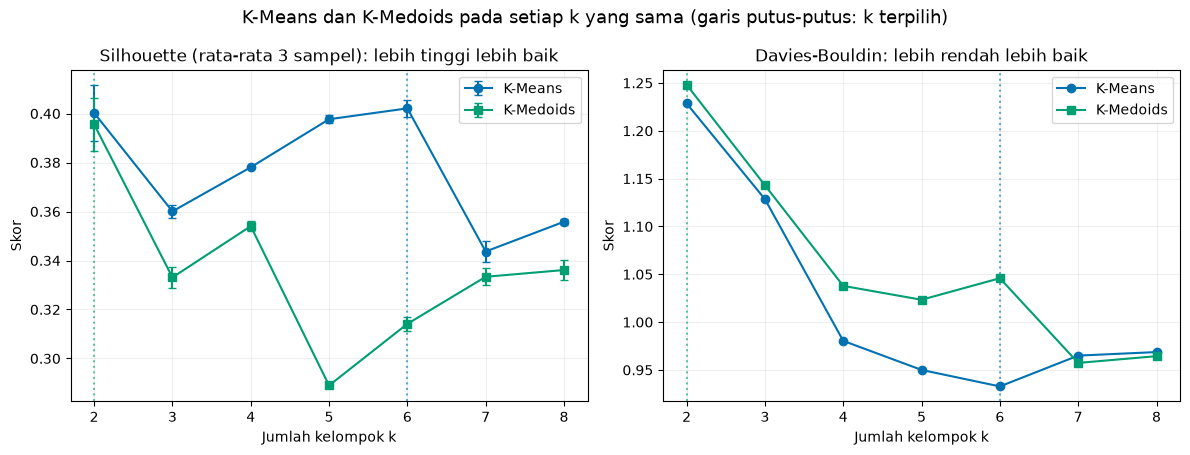

,k,Silhouette K-Means,Silhouette K-Medoids,DBI K-Means,DBI K-Medoids,Silhouette lebih tinggi,DBI lebih rendah
0,2,0.4003,0.3956,1.2286,1.2481,K-Means,K-Means
1,3,0.3601,0.3331,1.1285,1.1430,K-Means,K-Means
2,4,0.3781,0.3540,0.9804,1.0379,K-Means,K-Means
3,5,0.3977,0.2890,0.9500,1.0234,K-Means,K-Means
4,6,0.4021,0.3141,0.9328,1.0459,K-Means,K-Means
5,7,0.3437,0.3334,0.9650,0.9574,K-Means,K-Medoids
6,8,0.3558,0.3361,0.9687,0.9644,K-Means,K-Medoids


**Cara membaca:** setiap titik adalah rata-rata Silhouette tiga sampel; batang galat adalah simpangan baku antarsampel.
Pada k yang sama, K-Means memiliki Silhouette lebih tinggi pada **7 dari 7 nilai k** dan DBI lebih rendah pada **5 dari 7 nilai k**.
Perbandingan per k ini memisahkan pengaruh algoritma dari pengaruh jumlah kelompok. K-Medoids memilih k=2 karena aturan seleksi memberi Silhouette tertinggi pada k kecil,
bukan karena pembagian dua kelompok otomatis lebih informatif.


In [6]:
km_search = pd.read_csv(ROOT / "models/kmeans/parameter_search.csv").set_index("k")
kd_search = pd.read_csv(ROOT / "models/kmedoids/parameter_search.csv").set_index("k")
shared_k = sorted(set(km_search.index) & set(kd_search.index))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, metric, title in zip(axes, ["silhouette", "davies_bouldin"], ["Silhouette (rata-rata 3 sampel): lebih tinggi lebih baik", "Davies-Bouldin: lebih rendah lebih baik"]):
    ax.errorbar(shared_k, km_search.loc[shared_k, metric], yerr=km_search.loc[shared_k, "silhouette_std"] if metric == "silhouette" else None,
                marker="o", color=model_colors["kmeans"], label="K-Means", capsize=3)
    ax.errorbar(shared_k, kd_search.loc[shared_k, metric], yerr=kd_search.loc[shared_k, "silhouette_std"] if metric == "silhouette" else None,
                marker="s", color=model_colors["kmedoids"], label="K-Medoids", capsize=3)
    ax.axvline(km_model.n_clusters, color=model_colors["kmeans"], ls=":", alpha=.6)
    ax.axvline(kd_model.n_clusters, color=model_colors["kmedoids"], ls=":", alpha=.6)
    ax.set(xlabel="Jumlah kelompok k", ylabel="Skor", title=title)
    ax.grid(alpha=.2)
    ax.legend()
fig.suptitle("K-Means dan K-Medoids pada setiap k yang sama (garis putus-putus: k terpilih)", fontsize=13)
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/evaluation_k_curves.png", dpi=160)
plt.show()
plt.close(fig)
k_table = pd.DataFrame({"k": shared_k,
    "Silhouette K-Means": km_search.loc[shared_k, "silhouette"].to_numpy(), "Silhouette K-Medoids": kd_search.loc[shared_k, "silhouette"].to_numpy(),
    "DBI K-Means": km_search.loc[shared_k, "davies_bouldin"].to_numpy(), "DBI K-Medoids": kd_search.loc[shared_k, "davies_bouldin"].to_numpy()}).round(4)
k_table["Silhouette lebih tinggi"] = np.where(k_table["Silhouette K-Means"] >= k_table["Silhouette K-Medoids"], "K-Means", "K-Medoids")
k_table["DBI lebih rendah"] = np.where(k_table["DBI K-Means"] <= k_table["DBI K-Medoids"], "K-Means", "K-Medoids")
display(k_table)
silhouette_wins = int((k_table["Silhouette lebih tinggi"] == "K-Means").sum())
dbi_wins = int((k_table["DBI lebih rendah"] == "K-Means").sum())
display(Markdown(f"""**Cara membaca:** setiap titik adalah rata-rata Silhouette tiga sampel; batang galat adalah simpangan baku antarsampel.
Pada k yang sama, K-Means memiliki Silhouette lebih tinggi pada **{silhouette_wins} dari {len(k_table)} nilai k** dan DBI lebih rendah pada **{dbi_wins} dari {len(k_table)} nilai k**.
Perbandingan per k ini memisahkan pengaruh algoritma dari pengaruh jumlah kelompok. K-Medoids memilih k={kd_model.n_clusters} karena aturan seleksi memberi Silhouette tertinggi pada k kecil,
bukan karena pembagian dua kelompok otomatis lebih informatif.
"""))


<a id="s7"></a>
## 7. Grafik cakupan: masuk kelompok dan noise

Seluruh training layak menjadi penyebut di sini. Grafik menjawab berapa banyak data yang ditugaskan, bukan berapa banyak prediksi yang benar.

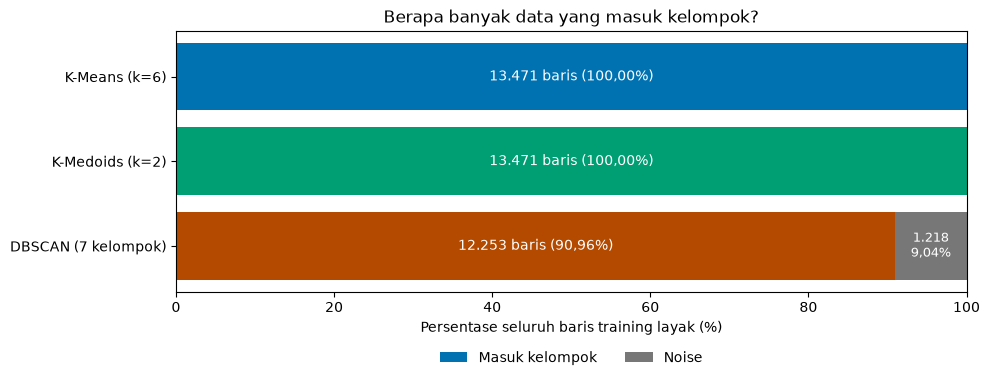

**Cara membaca:** panjang total setiap batang adalah 13.471 baris training layak.
K-Means dan K-Medoids selalu memberi kelompok; DBSCAN menempatkan 1.218 baris sebagai noise.
Karena itu 100% penugasan tidak berarti akurasi 100%, dan noise DBSCAN tidak otomatis berarti data salah.
Kotak tanpa kejadian tidak termasuk penyebut grafik ini karena tidak masuk training clustering.


In [7]:
coverage_models = main_models
assigned_counts = whole.loc[coverage_models, "n_assigned"].to_numpy(dtype=int)
noise_counts = whole.loc[coverage_models, "n_rows"].to_numpy(dtype=int) - assigned_counts
assigned_percent = assigned_counts / len(evaluation_train) * 100
noise_percent = noise_counts / len(evaluation_train) * 100
fig, ax = plt.subplots(figsize=(10, 4))
names = [model_names[key] for key in coverage_models]
ax.barh(names, assigned_percent, color=[model_colors[key] for key in coverage_models], label="Masuk kelompok")
ax.barh(names, noise_percent, left=assigned_percent, color="#777777", label="Noise")
for i, (assigned, noise) in enumerate(zip(assigned_counts, noise_counts)):
    ax.text(assigned_percent[i] / 2, i, f"{jumlah(assigned)} baris ({angka(assigned_percent[i], 2)}%)", ha="center", va="center", color="white")
    if noise:
        ax.text(assigned_percent[i] + noise_percent[i] / 2, i, jumlah(noise) + chr(10) + angka(noise_percent[i], 2) + "%", ha="center", va="center", color="white", fontsize=9)
ax.invert_yaxis()
ax.set(xlim=(0, 100), xlabel="Persentase seluruh baris training layak (%)", title="Berapa banyak data yang masuk kelompok?")
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.18), ncol=2, frameon=False)
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/evaluation_assignment_coverage.png", dpi=160)
plt.show()
plt.close(fig)
display(Markdown(f"""**Cara membaca:** panjang total setiap batang adalah {jumlah(len(evaluation_train))} baris training layak.
K-Means dan K-Medoids selalu memberi kelompok; DBSCAN menempatkan {jumlah(noise_counts[2])} baris sebagai noise.
Karena itu 100% penugasan tidak berarti akurasi 100%, dan noise DBSCAN tidak otomatis berarti data salah.
Kotak tanpa kejadian tidak termasuk penyebut grafik ini karena tidak masuk training clustering.
"""))


<a id="s8"></a>
## 8. Gambar hasil clustering ketiga model

Tiga model digambar pada sumbu yang sama, pertama pada proyeksi PCA lalu pada dua fitur asli (frekuensi dan kedalaman). Centroid K-Means dan medoid K-Medoids ditandai.

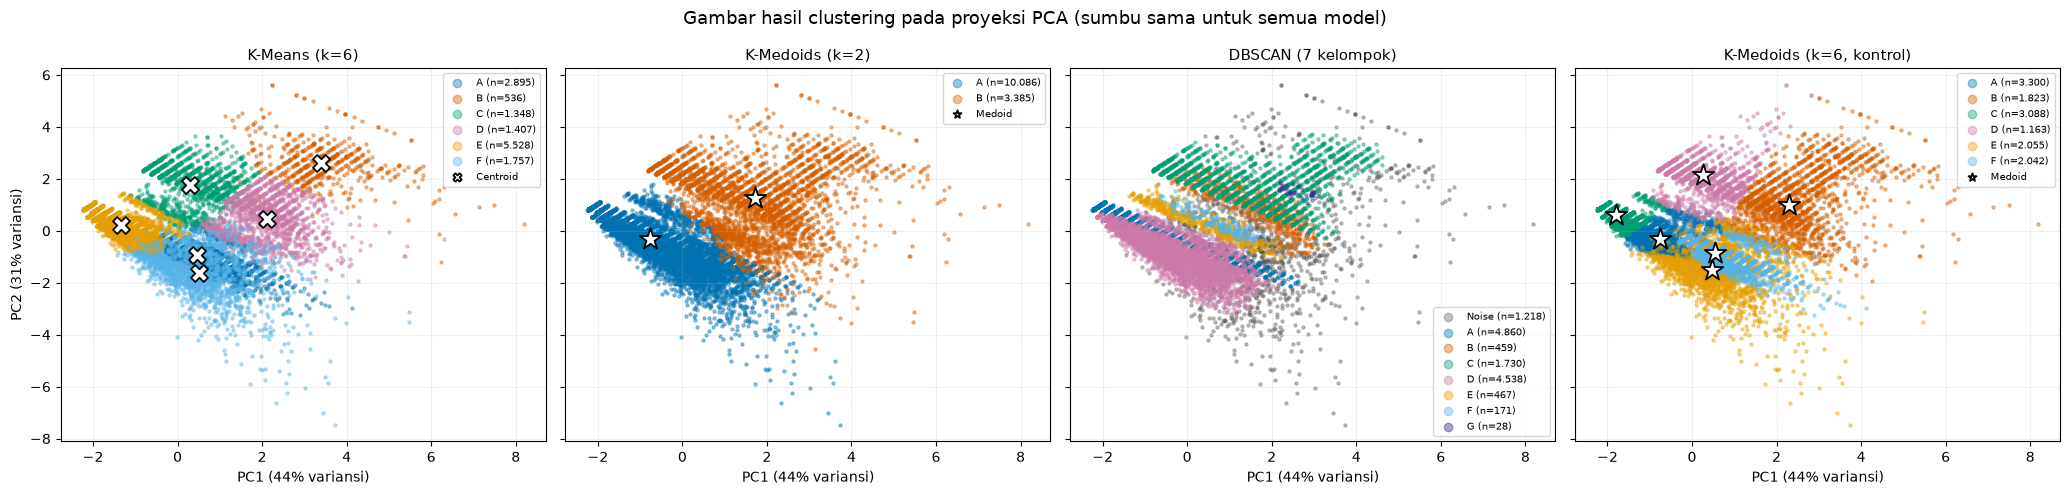

**Cara membaca:** satu titik adalah satu kotak-triwulan training. Warna adalah kelompok hasil algoritma dan huruf A, B, C hanya pengenal; warna yang sama pada panel berbeda bukan kelompok yang sama. Tanda X adalah centroid K-Means (titik rata-rata), bintang adalah medoid K-Medoids (observasi nyata). PCA hanya alat visual; model dilatih pada lima fitur standar penuh.

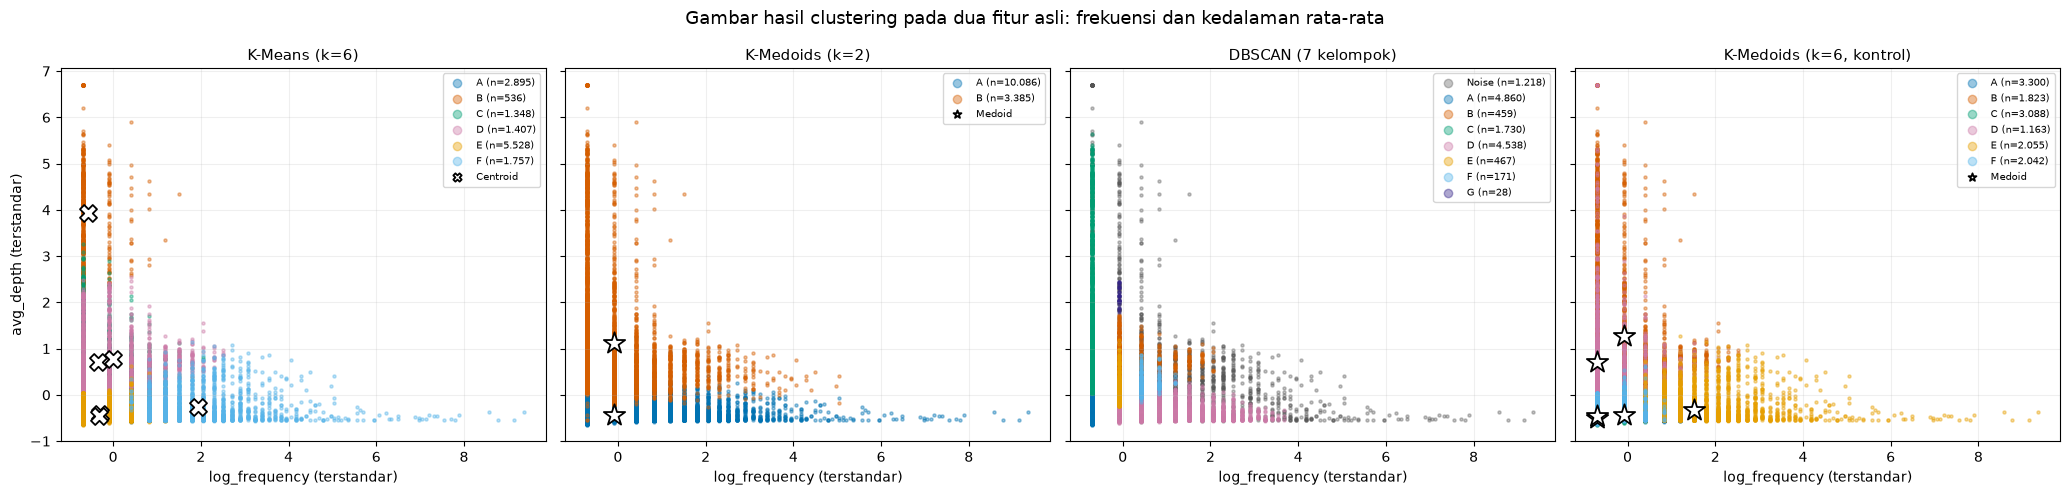

**Cara membaca:** sumbu adalah dua dari lima fitur terstandar, sehingga posisi titik langsung berarti frekuensi gempa dan kedalaman. Kedalaman membentuk dua gugus besar (dangkal dan dalam). Perhatikan apakah batas kelompok mengikuti struktur gugus itu atau memotong gugus yang sama menjadi beberapa bagian.

In [8]:
from sklearn.decomposition import PCA

palette = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#332288", "#882255"]
feature_names = list(evaluation_cfg["features"])
pca = PCA(n_components=2, random_state=42).fit(evaluation_X)
projection = pca.transform(evaluation_X)
centers = {"kmeans": km_model.cluster_centers_, "kmedoids": kd_model.cluster_centers_}
if has_control:
    centers["kmedoids_matched_k"] = evaluation_X[joblib.load(ROOT / "models/kmedoids/model_matched_k.joblib").medoid_indices_]

def draw_clusters(coordinates, center_coordinates, xlabel, ylabel, title, filename, note):
    columns = len(model_order)
    fig, axes = plt.subplots(1, columns, figsize=(5.2 * columns, 5), sharex=True, sharey=True)
    for ax, key in zip(np.atleast_1d(axes), model_order):
        labels_now = model_labels[key]
        noise_mask = labels_now < 0
        if noise_mask.any():
            ax.scatter(coordinates[noise_mask, 0], coordinates[noise_mask, 1], s=5, alpha=.35, color="#555555", label=f"Noise (n={jumlah(noise_mask.sum())})")
        for number in sorted(set(labels_now[~noise_mask].tolist())):
            mask = labels_now == number
            ax.scatter(coordinates[mask, 0], coordinates[mask, 1], s=5, alpha=.4, color=palette[number % len(palette)], label=f"{chr(65 + number)} (n={jumlah(mask.sum())})")
        if key in center_coordinates:
            marker, label = ("X", "Centroid") if key == "kmeans" else ("*", "Medoid")
            points = center_coordinates[key]
            ax.scatter(points[:, 0], points[:, 1], marker=marker, s=260 if marker == "*" else 150, color="white", edgecolor="black", linewidth=1.3, zorder=5, label=label)
        ax.set_title(model_names[key], fontsize=11)
        ax.set_xlabel(xlabel)
        ax.grid(alpha=.2)
        legend = ax.legend(fontsize=7.5, loc="best")
        for handle in legend.legend_handles:
            handle.set_sizes([36])
    np.atleast_1d(axes)[0].set_ylabel(ylabel)
    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    fig.savefig(ROOT / "reports/figures" / filename, dpi=160)
    plt.show()
    plt.close(fig)
    display(Markdown(note))

pca_centers = {key: pca.transform(value) for key, value in centers.items()}
draw_clusters(projection, pca_centers, f"PC1 ({pca.explained_variance_ratio_[0]:.0%} variansi)", f"PC2 ({pca.explained_variance_ratio_[1]:.0%} variansi)",
              "Gambar hasil clustering pada proyeksi PCA (sumbu sama untuk semua model)", "evaluation_cluster_visual_pca.png",
              "**Cara membaca:** satu titik adalah satu kotak-triwulan training. Warna adalah kelompok hasil algoritma dan huruf A, B, C hanya pengenal; warna yang sama pada panel berbeda bukan kelompok yang sama. Tanda X adalah centroid K-Means (titik rata-rata), bintang adalah medoid K-Medoids (observasi nyata). PCA hanya alat visual; model dilatih pada lima fitur standar penuh.")
i_frequency, i_depth = feature_names.index("log_frequency"), feature_names.index("avg_depth")
feature_centers = {key: value[:, [i_frequency, i_depth]] for key, value in centers.items()}
draw_clusters(evaluation_X[:, [i_frequency, i_depth]], feature_centers, "log_frequency (terstandar)", "avg_depth (terstandar)",
              "Gambar hasil clustering pada dua fitur asli: frekuensi dan kedalaman rata-rata", "evaluation_cluster_visual_features.png",
              "**Cara membaca:** sumbu adalah dua dari lima fitur terstandar, sehingga posisi titik langsung berarti frekuensi gempa dan kedalaman. Kedalaman membentuk dua gugus besar (dangkal dan dalam). Perhatikan apakah batas kelompok mengikuti struktur gugus itu atau memotong gugus yang sama menjadi beberapa bagian.")


<a id="s9"></a>
## 9. Diagram Silhouette per baris dan selang bootstrap

Diagram memperlihatkan kualitas setiap baris dan setiap kelompok, bukan hanya rata-rata. Selisih rata-rata antarmodel diberi selang bootstrap kasar.

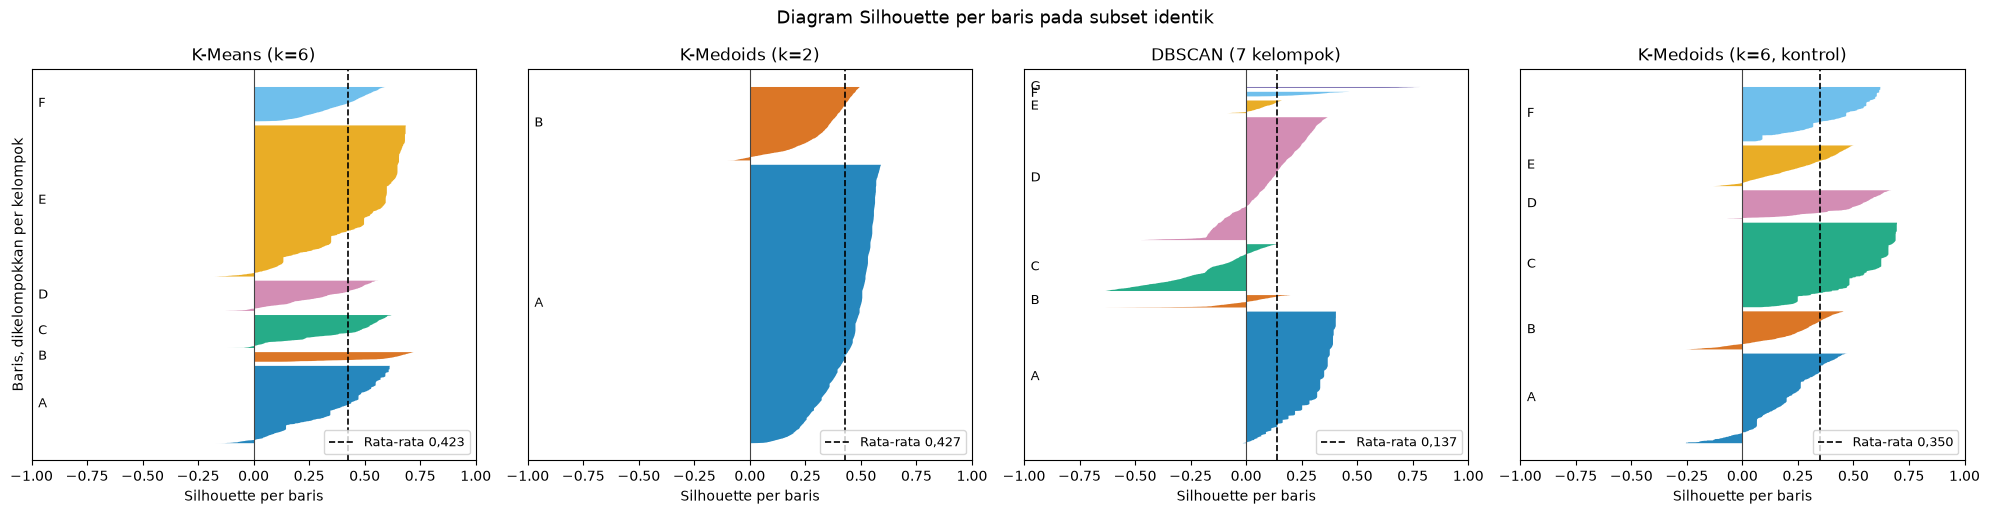

,Model,Rata-rata Silhouette,Median Silhouette,Baris Silhouette negatif (%),Kelompok dengan rata-rata < 0
0,K-Means (k=6),0.4227,0.4819,3.3216,0
1,K-Medoids (k=2),0.4267,0.4693,0.9875,0
2,DBSCAN (7 kelompok),0.1370,0.1567,23.7003,2
3,"K-Medoids (k=6, kontrol)",0.3499,0.3490,5.9904,0


,Selisih Silhouette (A - B),Selisih rata-rata,CI 95% bawah,CI 95% atas,CI tidak memuat 0
0,K-Means (k=6) - K-Medoids (k=2),-0.0040,-0.0077,-0.0003,True
1,K-Means (k=6) - DBSCAN (7 kelompok),0.2856,0.2803,0.2907,True
2,K-Medoids (k=2) - DBSCAN (7 kelompok),0.2897,0.2857,0.2937,True


**Cara membaca:** setiap lembar horizontal adalah satu kelompok; panjang ke kanan adalah Silhouette baris itu. Nilai negatif berarti baris lebih dekat ke kelompok lain daripada ke kelompoknya sendiri. Garis putus-putus adalah rata-rata seluruh baris, sehingga sedikit berbeda dari Silhouette tabel ringkasan yang memakai sampel tetap 2.000 baris.
Tabel kedua memberi selang kepercayaan bootstrap (2.000 pengambilan ulang baris) untuk selisih rata-rata Silhouette berpasangan pada baris yang sama.
Selang ini memperlakukan baris sebagai independen, padahal kotak bertetangga dan triwulan berurutan berkorelasi. Karena itu selang sebenarnya lebih lebar; gunakan sebagai indikasi kasar, bukan uji signifikansi formal.


In [9]:
from sklearn.metrics import silhouette_samples

X_common = evaluation_X[common]
sample_scores = {}
for key in model_order:
    sample_scores[key] = silhouette_samples(X_common, model_labels[key][common])
fig, axes = plt.subplots(1, len(model_order), figsize=(5 * len(model_order), 5.2), sharex=True)
for ax, key in zip(np.atleast_1d(axes), model_order):
    labels_now = model_labels[key][common]
    position = 0
    for number in sorted(set(labels_now.tolist())):
        values = np.sort(sample_scores[key][labels_now == number])
        ax.fill_betweenx(np.arange(position, position + len(values)), 0, values, color=palette[number % len(palette)], alpha=.85, linewidth=0)
        ax.text(-.97, position + len(values) / 2, chr(65 + number), va="center", fontsize=9)
        position += len(values) + 150
    ax.axvline(sample_scores[key].mean(), color="black", ls="--", lw=1.2, label=f"Rata-rata {angka(sample_scores[key].mean(), 3)}")
    ax.axvline(0, color="#444444", lw=.8)
    ax.set(xlim=(-1, 1), xlabel="Silhouette per baris", title=model_names[key], yticks=[])
    ax.legend(loc="lower right", fontsize=9)
np.atleast_1d(axes)[0].set_ylabel("Baris, dikelompokkan per kelompok")
fig.suptitle("Diagram Silhouette per baris pada subset identik", fontsize=13)
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/evaluation_silhouette_diagram.png", dpi=160)
plt.show()
plt.close(fig)
per_model = pd.DataFrame({
    "Model": [model_names[key] for key in model_order],
    "Rata-rata Silhouette": [sample_scores[key].mean() for key in model_order],
    "Median Silhouette": [np.median(sample_scores[key]) for key in model_order],
    "Baris Silhouette negatif (%)": [(sample_scores[key] < 0).mean() * 100 for key in model_order],
    "Kelompok dengan rata-rata < 0": [sum(sample_scores[key][model_labels[key][common] == number].mean() < 0 for number in set(model_labels[key][common].tolist())) for key in model_order],
}).round(4)
display(per_model)
rng = np.random.default_rng(evaluation_cfg["random_state"])
resample = rng.integers(0, len(X_common), size=(2000, len(X_common)))
pair_rows = []
for first, second in [("kmeans", "kmedoids"), ("kmeans", "dbscan"), ("kmedoids", "dbscan")]:
    difference = sample_scores[first] - sample_scores[second]
    boots = difference[resample].mean(axis=1)
    low, high = np.percentile(boots, [2.5, 97.5])
    pair_rows.append({"Selisih Silhouette (A - B)": f"{model_names[first]} - {model_names[second]}", "Selisih rata-rata": difference.mean(),
                      "CI 95% bawah": low, "CI 95% atas": high, "CI tidak memuat 0": bool(low > 0 or high < 0)})
bootstrap_table = pd.DataFrame(pair_rows).round(4)
display(bootstrap_table)
display(Markdown("""**Cara membaca:** setiap lembar horizontal adalah satu kelompok; panjang ke kanan adalah Silhouette baris itu. Nilai negatif berarti baris lebih dekat ke kelompok lain daripada ke kelompoknya sendiri. Garis putus-putus adalah rata-rata seluruh baris, sehingga sedikit berbeda dari Silhouette tabel ringkasan yang memakai sampel tetap 2.000 baris.
Tabel kedua memberi selang kepercayaan bootstrap (2.000 pengambilan ulang baris) untuk selisih rata-rata Silhouette berpasangan pada baris yang sama.
Selang ini memperlakukan baris sebagai independen, padahal kotak bertetangga dan triwulan berurutan berkorelasi. Karena itu selang sebenarnya lebih lebar; gunakan sebagai indikasi kasar, bukan uji signifikansi formal.
"""))


<a id="s10"></a>
## 10. Grafik jumlah anggota setiap kelompok

Bandingkan ukuran kelompok dan dukungan datanya. Huruf yang sama pada metode berbeda tidak berarti kelompok yang sama.

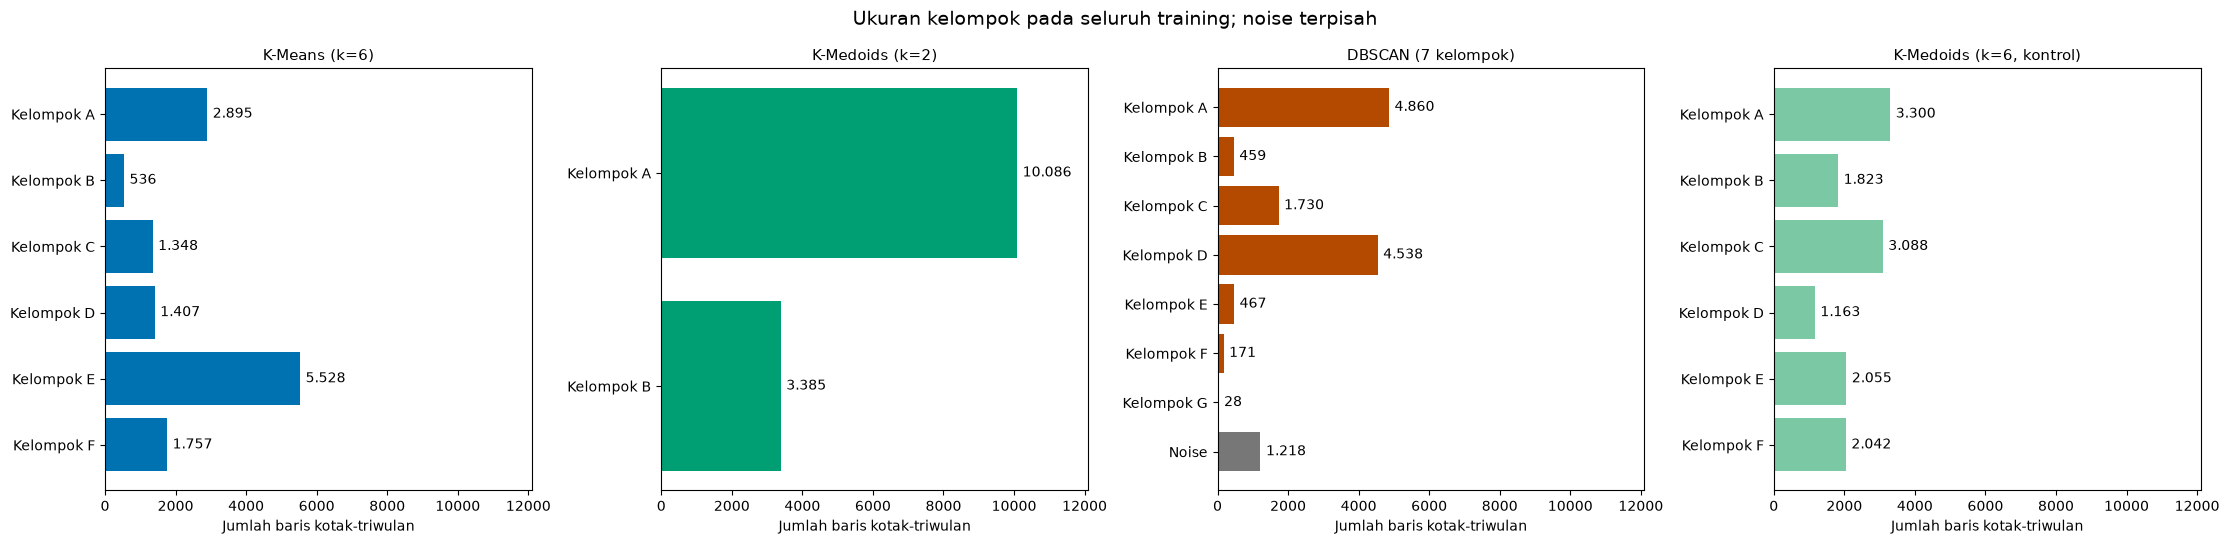

,Model,Kelompok,Terkecil (baris),Terbesar (% dari yang ditugaskan)
0,K-Means (k=6),6,536,41.04
1,K-Medoids (k=2),2,3385,74.87
2,DBSCAN (7 kelompok),7,28,39.66
3,"K-Medoids (k=6, kontrol)",6,1163,24.50


**Cara membaca:** lihat apakah ada kelompok sangat kecil atau satu kelompok yang mendominasi. Huruf A pada satu model tidak berarti kelompok yang sama dengan A pada model lain.
Huruf adalah pengenal, bukan peringkat bahaya. Jumlah kelompok lebih banyak juga tidak otomatis lebih baik.


In [10]:
fig, axes = plt.subplots(1, len(model_order), figsize=(5.6 * len(model_order), 5.5), sharex=True)
cluster_counts = {}
for ax, method in zip(np.atleast_1d(axes), model_order):
    unique, counts = np.unique(model_labels[method], return_counts=True)
    ordered = sorted(zip(unique, counts), key=lambda item: (item[0] < 0, item[0]))
    cluster_counts[method] = ordered
    names = ["Noise" if label < 0 else f"Kelompok {chr(65 + int(label))}" for label, _ in ordered]
    values = [count for _, count in ordered]
    bars = ax.barh(names, values, color=["#777777" if label < 0 else model_colors[method] for label, _ in ordered])
    ax.bar_label(bars, labels=[jumlah(value) for value in values], padding=4)
    ax.invert_yaxis()
    ax.set_title(model_names[method], fontsize=11)
    ax.set_xlabel("Jumlah baris kotak-triwulan")
maximum_count = max(count for entries in cluster_counts.values() for _, count in entries)
np.atleast_1d(axes)[0].set_xlim(0, maximum_count * 1.2)
fig.suptitle("Ukuran kelompok pada seluruh training; noise terpisah", fontsize=14)
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/evaluation_cluster_sizes.png", dpi=160)
plt.show()
plt.close(fig)
balance = pd.DataFrame({"Model": [model_names[key] for key in model_order],
    "Kelompok": [int(whole.loc[key, "n_clusters"]) for key in model_order],
    "Terkecil (baris)": [int(whole.loc[key, "smallest_cluster_size"]) for key in model_order],
    "Terbesar (% dari yang ditugaskan)": [whole.loc[key, "largest_cluster_fraction_assigned"] * 100 for key in model_order]}).round(2)
display(balance)
display(Markdown("""**Cara membaca:** lihat apakah ada kelompok sangat kecil atau satu kelompok yang mendominasi. Huruf A pada satu model tidak berarti kelompok yang sama dengan A pada model lain.
Huruf adalah pengenal, bukan peringkat bahaya. Jumlah kelompok lebih banyak juga tidak otomatis lebih baik.
"""))


<a id="s11"></a>
## 11. Grafik ciri kelompok dalam satuan asli

Grafik menampilkan rata-rata jumlah kejadian, magnitudo, dan kedalaman agar ciri kelompok mudah dibaca. Grafik pada kolom yang sama menggunakan skala sumbu yang sama.

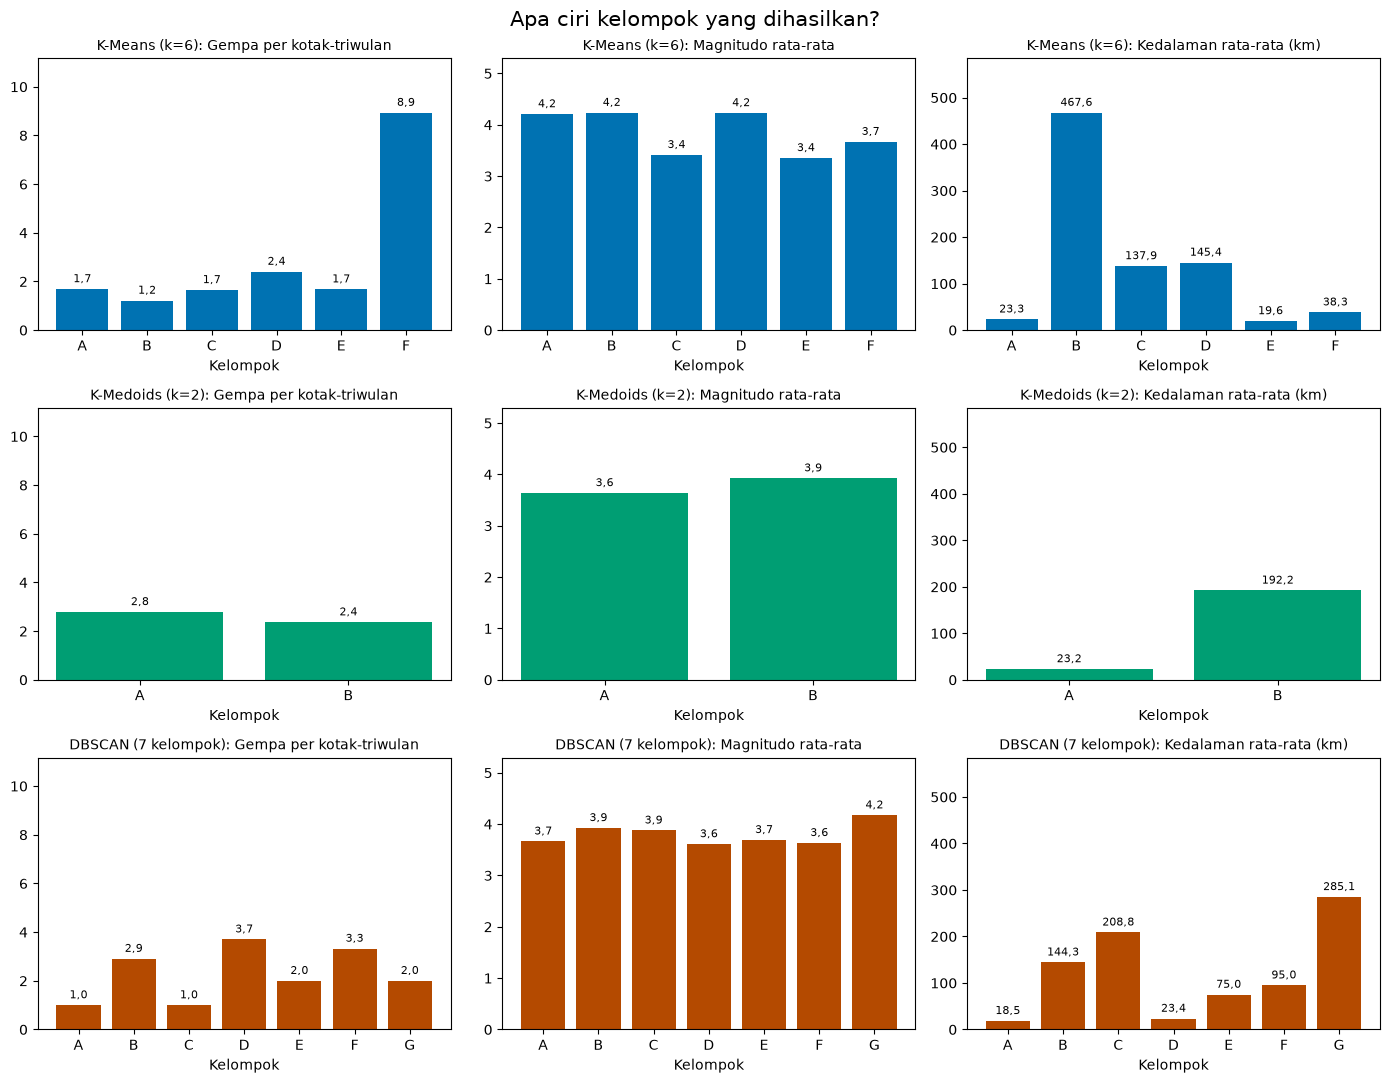

**Cara membaca:** bandingkan kolom yang sama karena satuannya sama. Kolom kiri adalah rata-rata jumlah gempa, tengah magnitudo, kanan kedalaman. Angka merangkum rata-rata baris kotak-triwulan anggota kelompok, bukan setiap kejadian memiliki nilai yang sama. Huruf tidak berpasangan antarmodel. Grafik memakai tiga ciri dalam satuan asli; model tetap memakai lima fitur standar. Noise dikeluarkan dari grafik; statistiknya ada pada tabel profil.

In [11]:
profile_frames = {method: pd.read_csv(ROOT / f"models/{method}/profiles.csv") for method in main_models}
profile_columns = ["earthquake_count", "avg_magnitude", "avg_depth"]
profile_titles = ["Gempa per kotak-triwulan", "Magnitudo rata-rata", "Kedalaman rata-rata (km)"]
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for row, method in enumerate(main_models):
    frame = profile_frames[method].loc[lambda data: data["profile"].ne("NOISE")].copy()
    names = frame["profile"].map(lambda code: chr(65 + int(code.rsplit("P", 1)[1])))
    for col, (feature, title) in enumerate(zip(profile_columns, profile_titles)):
        ax = axes[row, col]
        bars = ax.bar(names, frame[feature], color=model_colors[method])
        ax.bar_label(bars, labels=[angka(value, 1) for value in frame[feature]], padding=3, fontsize=8)
        max_value = max(profile_frames[m].loc[lambda data: data["profile"].ne("NOISE"), feature].max() for m in profile_frames)
        ax.set_ylim(0, max_value * 1.25)
        ax.set_title(f"{model_names[method]}: {title}", fontsize=10)
        ax.set_xlabel("Kelompok")
fig.suptitle("Apa ciri kelompok yang dihasilkan?", fontsize=15)
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/evaluation_profile_characteristics.png", dpi=160)
plt.show()
plt.close(fig)
display(Markdown("**Cara membaca:** bandingkan kolom yang sama karena satuannya sama. Kolom kiri adalah rata-rata jumlah gempa, tengah magnitudo, kanan kedalaman. Angka merangkum rata-rata baris kotak-triwulan anggota kelompok, bukan setiap kejadian memiliki nilai yang sama. Huruf tidak berpasangan antarmodel. Grafik memakai tiga ciri dalam satuan asli; model tetap memakai lima fitur standar. Noise dikeluarkan dari grafik; statistiknya ada pada tabel profil."))


<a id="s12"></a>
## 12. Grafik kesepakatan pengelompokan dan ARI

Periksa bagaimana baris yang sama dibagi oleh metode yang berbeda. Tidak ada label jawaban benar, sehingga grafik ini tidak digunakan untuk menghitung akurasi.

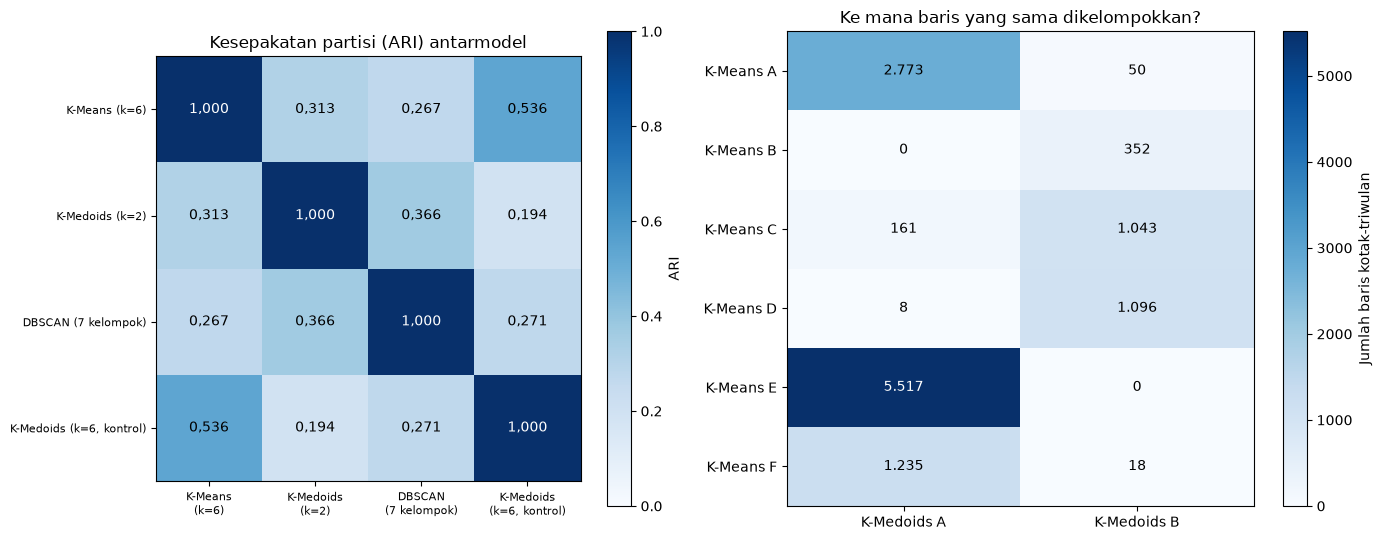

**Cara membaca:** ARI memakai 12.253 baris yang sama tanpa noise DBSCAN. ARI 1 berarti partisi identik walaupun nama label berbeda; sekitar 0 setara kesepakatan acak.
Panel kanan menunjukkan sebaran baris K-Means ke kelompok K-Medoids; sel gelap berarti banyak baris berbagi pasangan kelompok itu.
**Ini bukan confusion matrix akurasi:** tidak ada kelompok jawaban benar, sehingga diagonal tidak berarti benar atau salah.
ARI K-Means dengan K-Medoids adalah **0,313**, K-Means dengan DBSCAN **0,267**,
dan K-Medoids dengan DBSCAN **0,366**.
ARI rendah pada jumlah kelompok berbeda sebagian disebabkan oleh perbedaan granularitas, bukan hanya perbedaan batas kelompok.


In [12]:
import json

agreement = json.loads((ROOT / "reports/evaluation/agreement.json").read_text(encoding="utf-8"))
ari_matrix = pd.DataFrame(1.0, index=model_order, columns=model_order)
for pair, values in agreement["pairwise_ari"].items():
    first, second = pair.split("_vs_")
    ari_matrix.loc[first, second] = ari_matrix.loc[second, first] = values["ari_common_assigned"]
assert agreement["n_common_assigned"] == int(common.sum())
agreement_counts = pd.crosstab(pd.Series(km_model.labels_[common], name="K-Means"), pd.Series(kd_model.labels_[common], name="K-Medoids"))
assert agreement_counts.to_numpy().sum() == common.sum()
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.1]})
image = axes[0].imshow(ari_matrix.to_numpy(), cmap="Blues", vmin=0, vmax=1)
for i in range(len(model_order)):
    for j in range(len(model_order)):
        axes[0].text(j, i, angka(ari_matrix.iloc[i, j], 3), ha="center", va="center", color="white" if ari_matrix.iloc[i, j] > .6 else "black")
axes[0].set_xticks(range(len(model_order)), [model_names[key].replace(" (", chr(10) + "(") for key in model_order], fontsize=8)
axes[0].set_yticks(range(len(model_order)), [model_names[key] for key in model_order], fontsize=8)
axes[0].set_title("Kesepakatan partisi (ARI) antarmodel")
fig.colorbar(image, ax=axes[0], label="ARI")
heat = axes[1].imshow(agreement_counts, cmap="Blues", aspect="auto", vmin=0)
for i in range(len(agreement_counts.index)):
    for j in range(len(agreement_counts.columns)):
        count = agreement_counts.iloc[i, j]
        axes[1].text(j, i, jumlah(count), ha="center", va="center", color="white" if count > agreement_counts.to_numpy().max() * .55 else "black")
axes[1].set_xticks(range(len(agreement_counts.columns)), [f"K-Medoids {chr(65 + int(label))}" for label in agreement_counts.columns])
axes[1].set_yticks(range(len(agreement_counts.index)), [f"K-Means {chr(65 + int(label))}" for label in agreement_counts.index])
axes[1].set_title("Ke mana baris yang sama dikelompokkan?")
fig.colorbar(heat, ax=axes[1], label="Jumlah baris kotak-triwulan")
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/evaluation_partition_overlap.png", dpi=160)
plt.show()
plt.close(fig)
display(Markdown(f"""**Cara membaca:** ARI memakai {jumlah(common.sum())} baris yang sama tanpa noise DBSCAN. ARI 1 berarti partisi identik walaupun nama label berbeda; sekitar 0 setara kesepakatan acak.
Panel kanan menunjukkan sebaran baris K-Means ke kelompok K-Medoids; sel gelap berarti banyak baris berbagi pasangan kelompok itu.
**Ini bukan confusion matrix akurasi:** tidak ada kelompok jawaban benar, sehingga diagonal tidak berarti benar atau salah.
ARI K-Means dengan K-Medoids adalah **{angka(ari_matrix.loc['kmeans', 'kmedoids'], 3)}**, K-Means dengan DBSCAN **{angka(ari_matrix.loc['kmeans', 'dbscan'], 3)}**,
dan K-Medoids dengan DBSCAN **{angka(ari_matrix.loc['kmedoids', 'dbscan'], 3)}**.
ARI rendah pada jumlah kelompok berbeda sebagian disebabkan oleh perbedaan granularitas, bukan hanya perbedaan batas kelompok.
"""))


<a id="s13"></a>
## 13. Kestabilan terhadap subsampel data

Setiap model dilatih ulang pada 80% baris acak dengan parameter tetap, lalu dibandingkan dengan label referensi. Uji ini mengukur kepekaan terhadap sampel data, bukan kebenaran hasil.

,ari_common_mean,ari_common_sd,ari_with_noise_mean,common_assigned_fraction,clusters_min,clusters_max
K-Means (k=6),0.9896,0.0037,0.9896,1.000,6,6
K-Medoids (k=2),0.9932,0.0084,0.9932,1.000,2,2
DBSCAN (7 kelompok),0.9998,0.0002,0.9749,0.891,6,8


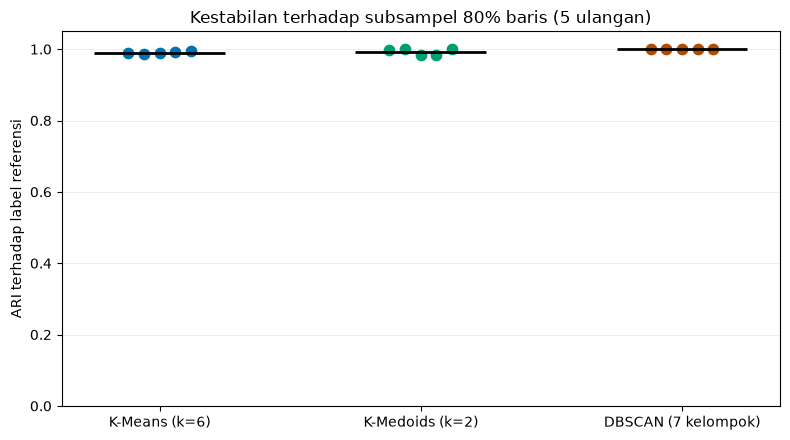

**Cara membaca:** setiap model dilatih ulang pada 80% baris acak (seed [7, 21, 42, 84, 123]), lalu labelnya dibandingkan dengan label referensi pada 80% baris yang sama.
Titik adalah satu ulangan dan garis hitam adalah rata-rata. ARI memakai baris yang ditugaskan pada kedua partisi; kolom `common_assigned_fraction` memperlihatkan seberapa banyak baris itu.
Parameter model tidak disetel ulang: k tetap untuk K-Means dan K-Medoids, serta eps dan min_samples tetap untuk DBSCAN. Uji ini hanya mengukur kepekaan terhadap sampel data.
Uji sensitivitas lain (k, grid, ambang magnitudo, dukungan minimum) ada di notebook 09.


In [13]:
subsample = subsample_stability(ROOT)
stability_summary = subsample.groupby("method").agg(
    ari_common_mean=("ari_common_assigned", "mean"), ari_common_sd=("ari_common_assigned", "std"),
    ari_with_noise_mean=("ari_including_noise", "mean"), common_assigned_fraction=("common_assigned_fraction", "mean"),
    clusters_min=("n_clusters", "min"), clusters_max=("n_clusters", "max")).loc[main_models]
stability_summary.index = [model_names[key] for key in main_models]
display(stability_summary.round(4))
fig, ax = plt.subplots(figsize=(8, 4.5))
for position, key in enumerate(main_models):
    values = subsample.loc[subsample["method"].eq(key), "ari_common_assigned"].to_numpy()
    ax.scatter(np.full(len(values), position) + np.linspace(-.12, .12, len(values)), values, color=model_colors[key], s=55, zorder=3)
    ax.hlines(values.mean(), position - .25, position + .25, color="black", lw=2, zorder=4)
ax.set_xticks(range(len(main_models)), [model_names[key] for key in main_models])
ax.set(ylabel="ARI terhadap label referensi", ylim=(0, 1.05), title=f"Kestabilan terhadap subsampel 80% baris ({len(evaluation_cfg['stability_seeds'])} ulangan)")
ax.grid(axis="y", alpha=.2)
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/evaluation_subsample_stability.png", dpi=160)
plt.show()
plt.close(fig)
display(Markdown(f"""**Cara membaca:** setiap model dilatih ulang pada 80% baris acak (seed {evaluation_cfg['stability_seeds']}), lalu labelnya dibandingkan dengan label referensi pada 80% baris yang sama.
Titik adalah satu ulangan dan garis hitam adalah rata-rata. ARI memakai baris yang ditugaskan pada kedua partisi; kolom `common_assigned_fraction` memperlihatkan seberapa banyak baris itu.
Parameter model tidak disetel ulang: k tetap untuk K-Means dan K-Medoids, serta eps dan min_samples tetap untuk DBSCAN. Uji ini hanya mengukur kepekaan terhadap sampel data.
Uji sensitivitas lain (k, grid, ambang magnitudo, dukungan minimum) ada di notebook 09.
"""))


<a id="s14"></a>
## 14. Peringkat model berdasarkan banyak kriteria

Enam kriteria diperingkat per model: tiga skor internal, proporsi baris Silhouette negatif, kestabilan subsampel, dan cakupan data. Rata-rata peringkat diringkas dua cara: hanya kualitas klaster, dan seluruh kriteria.

In [14]:
def tolerant_rank(values, higher_is_better, tolerance=0.0):
    """Peringkat 1 = terbaik; model dianggap seri jika selisih nilainya tidak melebihi toleransi."""
    values, sign = np.asarray(values, dtype=float), (1 if higher_is_better else -1)
    return [1 + int(sum(sign * (values[j] - values[i]) > tolerance for j in range(len(values)))) for i in range(len(values))]

selected_sd = max(km_search.loc[km_model.n_clusters, "silhouette_std"], kd_search.loc[kd_model.n_clusters, "silhouette_std"])
criteria = pd.DataFrame(index=main_models)
criteria["Silhouette (naik)"] = fair.loc[main_models, "silhouette"]
criteria["Davies-Bouldin (turun)"] = fair.loc[main_models, "davies_bouldin"]
criteria["Calinski-Harabasz (naik)"] = fair.loc[main_models, "calinski_harabasz"]
criteria["Baris Silhouette negatif % (turun)"] = [(sample_scores[key] < 0).mean() * 100 for key in main_models]
criteria["Kestabilan subsampel ARI (naik)"] = subsample.groupby("method")["ari_common_assigned"].mean().loc[main_models]
criteria["Cakupan data % (naik)"] = [whole.loc[key, "n_assigned"] / len(evaluation_train) * 100 for key in main_models]
higher_is_better = {"Silhouette (naik)": True, "Davies-Bouldin (turun)": False, "Calinski-Harabasz (naik)": True,
                    "Baris Silhouette negatif % (turun)": False, "Kestabilan subsampel ARI (naik)": True, "Cakupan data % (naik)": True}
tolerance = {"Silhouette (naik)": selected_sd, "Kestabilan subsampel ARI (naik)": 0.01, "Cakupan data % (naik)": 0.5}
ranks = pd.DataFrame({column: tolerant_rank(criteria[column], higher_is_better[column], tolerance.get(column, 0.0)) for column in criteria.columns}, index=main_models)
quality_columns = [column for column in criteria.columns if column != "Cakupan data % (naik)"]
ranks["Rata-rata peringkat (kualitas klaster)"] = ranks[quality_columns].mean(axis=1)
ranks["Rata-rata peringkat (semua kriteria)"] = ranks[list(criteria.columns)].mean(axis=1)
display(Markdown("### Nilai kriteria (subset identik, kecuali cakupan yang memakai seluruh training)"))
display(criteria.rename(index=model_names).round(4))
display(Markdown(f"""### Peringkat per kriteria (1 = terbaik)

Selisih dianggap **seri** bila tidak melebihi toleransi: Silhouette {angka(selected_sd, 4)} (simpangan baku antarsampel Silhouette pada seleksi k), kestabilan ARI 0,01, cakupan 0,5 poin persen.
DBI, Calinski-Harabasz, dan proporsi baris negatif dihitung pada seluruh baris sehingga tanpa toleransi.
"""))
display(ranks.rename(index=model_names).round(2))
best_quality = ranks["Rata-rata peringkat (kualitas klaster)"].min()
quality_tied = [key for key in main_models if np.isclose(ranks.loc[key, "Rata-rata peringkat (kualitas klaster)"], best_quality)]

control_key = "kmedoids_matched_k" if has_control else "kmedoids"
same_k = pd.DataFrame({"Silhouette": fair.loc[["kmeans", control_key], "silhouette"], "Davies-Bouldin": fair.loc[["kmeans", control_key], "davies_bouldin"],
                       "Calinski-Harabasz": fair.loc[["kmeans", control_key], "calinski_harabasz"],
                       "Baris Silhouette negatif %": [(sample_scores[key] < 0).mean() * 100 for key in ["kmeans", control_key]]})
same_k.index = [model_names["kmeans"], model_names[control_key]]
display(Markdown(f"### Kontrol granularitas: K-Means dan K-Medoids pada jumlah kelompok yang sama (k={km_model.n_clusters})"))
display(same_k.round(4))
kmeans_wins_same_k = {"Silhouette": same_k.iloc[0]["Silhouette"] > same_k.iloc[1]["Silhouette"], "Davies-Bouldin": same_k.iloc[0]["Davies-Bouldin"] < same_k.iloc[1]["Davies-Bouldin"],
                      "Calinski-Harabasz": same_k.iloc[0]["Calinski-Harabasz"] > same_k.iloc[1]["Calinski-Harabasz"],
                      "Baris Silhouette negatif %": same_k.iloc[0]["Baris Silhouette negatif %"] < same_k.iloc[1]["Baris Silhouette negatif %"]}
kmeans_same_k_all = all(kmeans_wins_same_k.values())
if len(quality_tied) == 1:
    recommended = quality_tied[0]
    tie_note = "Peringkat kualitas klaster menempatkan satu model di depan."
elif set(quality_tied) == {"kmeans", "kmedoids"} and kmeans_same_k_all:
    recommended = "kmeans"
    tie_note = "Peringkat kualitas klaster seri antara K-Means dan K-Medoids; seri dipecahkan oleh kontrol granularitas, tempat K-Means unggul pada keempat ukuran."
else:
    recommended = None
    tie_note = "Peringkat kualitas klaster seri dan kontrol granularitas tidak memecahkan seri."
display(Markdown(f"""**Hasil peringkat:** {tie_note}
Rekomendasi model utama: **{model_names[recommended] if recommended else 'tidak ada satu model yang jelas unggul'}**.
Peringkat memberi bobot sama pada setiap kriteria; ini ringkasan deskriptif dan bukan uji statistik.
Kestabilan subsampel cenderung lebih tinggi untuk partisi kasar (k kecil), sehingga kriteria itu tidak boleh dibaca terpisah dari jumlah kelompok.
"""))


### Nilai kriteria (subset identik, kecuali cakupan yang memakai seluruh training)

,Silhouette (naik),Davies-Bouldin (turun),Calinski-Harabasz (naik),Baris Silhouette negatif % (turun),Kestabilan subsampel ARI (naik),Cakupan data % (naik)
K-Means (k=6),0.4257,0.8665,7441.8936,3.3216,0.9896,100.0000
K-Medoids (k=2),0.4298,1.1103,6007.1899,0.9875,0.9932,100.0000
DBSCAN (7 kelompok),0.1261,2.0116,1776.2069,23.7003,0.9998,90.9584


### Peringkat per kriteria (1 = terbaik)

Selisih dianggap **seri** bila tidak melebihi toleransi: Silhouette 0,0108 (simpangan baku antarsampel Silhouette pada seleksi k), kestabilan ARI 0,01, cakupan 0,5 poin persen.
DBI, Calinski-Harabasz, dan proporsi baris negatif dihitung pada seluruh baris sehingga tanpa toleransi.


,Silhouette (naik),Davies-Bouldin (turun),Calinski-Harabasz (naik),Baris Silhouette negatif % (turun),Kestabilan subsampel ARI (naik),Cakupan data % (naik),Rata-rata peringkat (kualitas klaster),Rata-rata peringkat (semua kriteria)
K-Means (k=6),1,1,1,2,2,1,1.4,1.33
K-Medoids (k=2),1,2,2,1,1,1,1.4,1.33
DBSCAN (7 kelompok),3,3,3,3,1,3,2.6,2.67


### Kontrol granularitas: K-Means dan K-Medoids pada jumlah kelompok yang sama (k=6)

,Silhouette,Davies-Bouldin,Calinski-Harabasz,Baris Silhouette negatif %
K-Means (k=6),0.4257,0.8665,7441.8936,3.3216
"K-Medoids (k=6, kontrol)",0.3472,1.0078,7261.1127,5.9904


**Hasil peringkat:** Peringkat kualitas klaster seri antara K-Means dan K-Medoids; seri dipecahkan oleh kontrol granularitas, tempat K-Means unggul pada keempat ukuran.
Rekomendasi model utama: **K-Means (k=6)**.
Peringkat memberi bobot sama pada setiap kriteria; ini ringkasan deskriptif dan bukan uji statistik.
Kestabilan subsampel cenderung lebih tinggi untuk partisi kasar (k kecil), sehingga kriteria itu tidak boleh dibaca terpisah dari jumlah kelompok.


<a id="s15"></a>
## 15. Kesimpulan evaluasi, batas hasil, dan langkah berikutnya

Baca kesimpulan bersama cakupan data, ciri kelompok, dan uji sensitivitas. Satu skor tidak cukup untuk membuktikan kebenaran geologis suatu pengelompokan.

In [15]:
ks = lambda key: model_names[key]
from src.mapping import profile_descriptions

rivals = [key for key in main_models if key != "dbscan"]
assert (fair.loc["dbscan", "silhouette"] < fair.loc[rivals, "silhouette"]).all(), "Klaim 'DBSCAN terlemah menurut Silhouette' tidak berlaku pada hasil ini."
assert (fair.loc["dbscan", "davies_bouldin"] > fair.loc[rivals, "davies_bouldin"]).all(), "Klaim 'DBSCAN terlemah menurut DBI' tidak berlaku pada hasil ini."
assert (fair.loc["dbscan", "calinski_harabasz"] < fair.loc[rivals, "calinski_harabasz"]).all(), "Klaim 'DBSCAN terlemah menurut CH' tidak berlaku pada hasil ini."
assert recommended is not None, "Tidak ada model yang jelas unggul; kesimpulan akademik harus ditulis ulang."
assert kmeans_same_k_all, "Teks kontrol granularitas mengasumsikan K-Means unggul pada k yang sama."
negative_groups = per_model.set_index("Model")["Kelompok dengan rata-rata < 0"]
stability_floor = stability_summary["ari_common_mean"].min()
ari_values = [ari_matrix.loc[a, b] for a, b in [("kmeans", "kmedoids"), ("kmeans", "dbscan"), ("kmedoids", "dbscan")]]
assert kd_model.n_clusters < km_model.n_clusters, "Teks tentang granularitas K-Medoids mengasumsikan k lebih kecil dari K-Means."
kd_profiles = pd.read_csv(ROOT / "models/kmedoids/profiles.csv")
kd_profiles = kd_profiles.loc[kd_profiles["profile"].str.contains("_P", regex=False)]
depth_span = kd_profiles["avg_depth"].max() - kd_profiles["avg_depth"].min()
count_span = kd_profiles["earthquake_count"].max() - kd_profiles["earthquake_count"].min()
magnitude_span = kd_profiles["avg_magnitude"].max() - kd_profiles["avg_magnitude"].min()
kd_depth_text = (f"Kelompok K-Medoids terutama memisahkan kedalaman: rata-rata kedalaman antarkelompok berselisih {angka(depth_span, 0)} km ({angka(kd_profiles['avg_depth'].min(), 0)} sampai {angka(kd_profiles['avg_depth'].max(), 0)} km), "
                 f"sedangkan selisih rata-rata jumlah gempa hanya {angka(count_span, 2)} per kotak-triwulan dan selisih magnitudo {angka(magnitude_span, 2)}.") if depth_span > 100 else "Kelompok K-Medoids tidak didominasi satu fitur kedalaman."
same_k_values = same_k.round(4)
noise_pct = whole.loc["dbscan", "noise_fraction"] * 100
display(Markdown(f"""### Kesimpulan akademik perbandingan tiga model

**1. Keterpisahan dan kekompakan kelompok (subset identik, {jumlah(common.sum())} baris).**
Silhouette: {ks('kmeans')} = {angka(fair.loc['kmeans', 'silhouette'])}, {ks('kmedoids')} = {angka(fair.loc['kmedoids', 'silhouette'])}, {ks('dbscan')} = {angka(fair.loc['dbscan', 'silhouette'])}.
DBI: {angka(fair.loc['kmeans', 'davies_bouldin'])}, {angka(fair.loc['kmedoids', 'davies_bouldin'])}, dan {angka(fair.loc['dbscan', 'davies_bouldin'])} (berturut-turut).
Calinski-Harabasz: {angka(fair.loc['kmeans', 'calinski_harabasz'], 0)}, {angka(fair.loc['kmedoids', 'calinski_harabasz'], 0)}, dan {angka(fair.loc['dbscan', 'calinski_harabasz'], 0)}.
{silhouette_note[0].upper() + silhouette_note[1:]} untuk Silhouette. DBSCAN paling lemah pada ketiga ukuran. Baris dengan Silhouette negatif (lebih dekat ke kelompok lain): {angka((sample_scores['kmeans'] < 0).mean() * 100, 2)}% untuk K-Means, {angka((sample_scores['kmedoids'] < 0).mean() * 100, 2)}% untuk K-Medoids, dan {angka((sample_scores['dbscan'] < 0).mean() * 100, 2)}% untuk DBSCAN.

**2. Pengaruh jumlah kelompok (kontrol granularitas).**
K-Medoids memilih k={kd_model.n_clusters} dan K-Means k={km_model.n_clusters}, sehingga skor keduanya tidak boleh dibaca sebagai efek algoritma saja. {kd_depth_text}
Pada **k yang sama ({km_model.n_clusters})**, K-Means lebih baik daripada K-Medoids pada Silhouette ({angka(same_k_values.iloc[0]['Silhouette'])} berbanding {angka(same_k_values.iloc[1]['Silhouette'])}), DBI ({angka(same_k_values.iloc[0]['Davies-Bouldin'])} berbanding {angka(same_k_values.iloc[1]['Davies-Bouldin'])}), Calinski-Harabasz, dan proporsi baris Silhouette negatif.
Pada seluruh k=2..8 (bagian 6), K-Means memiliki Silhouette lebih tinggi pada {silhouette_wins} dari {len(k_table)} nilai k dan DBI lebih rendah pada {dbi_wins} dari {len(k_table)} nilai k.

**3. Cakupan dan noise.**
K-Means dan K-Medoids menugaskan 100% baris. DBSCAN meninggalkan {angka(noise_pct, 2)}% sebagai noise dan membentuk kelompok terkecil {jumlah(whole.loc['dbscan', 'smallest_cluster_size'])} baris.
Noise adalah informasi (baris yang tidak masuk struktur kepadatan), tetapi untuk pemetaan wilayah penuh ia menyisakan kotak tanpa profil.

**4. Gambar hasil clustering (bagian 8-9).**
Secara visual, titik-titik membentuk kontinum tanpa celah kepadatan yang tegas. Ini interpretasi dari gambar yang sejalan dengan sulitnya DBSCAN menemukan parameter yang menghasilkan kelompok bersih; bukan uji formal. Pada proyeksi PCA, kelompok DBSCAN saling tumpang tindih dan noise tersebar di tepi serta area campuran. Beberapa kelompok K-Means juga tampak bertumpuk karena proyeksi 2D meringkas lima dimensi. K-Medoids pada k={kd_model.n_clusters} memotong kontinum menjadi dua bagian besar.
Diagram Silhouette: jumlah kelompok dengan rata-rata Silhouette negatif adalah {int(negative_groups[ks('kmeans')])} pada K-Means, {int(negative_groups[ks('kmedoids')])} pada K-Medoids, dan {int(negative_groups[ks('dbscan')])} pada DBSCAN.

**5. Kestabilan terhadap sampel data (fit ulang pada 80% baris).**
ARI rata-rata: {ks('kmeans')} = {angka(stability_summary.iloc[0]['ari_common_mean'], 3)}, {ks('kmedoids')} = {angka(stability_summary.iloc[1]['ari_common_mean'], 3)}, {ks('dbscan')} = {angka(stability_summary.iloc[2]['ari_common_mean'], 3)}.
Ketiganya stabil (terendah {angka(stability_floor, 3)}). ARI dihitung hanya pada baris yang ditugaskan pada kedua partisi, dan partisi kasar seperti K-Medoids k={kd_model.n_clusters} lebih mudah direproduksi. Kriteria ini tidak membedakan model dengan tajam dan tidak boleh dibaca terpisah dari jumlah kelompok.

**6. Kesepakatan antarmodel (bagian 12).**
ARI antarmodel pada baris yang sama berkisar {angka(min(ari_values), 3)} sampai {angka(max(ari_values), 3)} (rendah), sehingga ketiga metode tidak membagi data dengan cara yang sama.

### Penilaian yang dapat dipertanggungjawabkan

- **Model utama yang direkomendasikan untuk laporan: {ks(recommended)}.** {tie_note} Rekomendasi ini berlaku pada fitur, jarak Euclidean, dan kandidat parameter penelitian ini.
- **K-Medoids** setara dengan K-Means pada Silhouette (dalam batas simpangan baku sampel), tetapi pada k yang jauh lebih kecil sehingga partisinya kasar. Pada granularitas yang sama ia lebih lemah. Keunggulannya bersifat non-skor: pusat berupa kotak-triwulan nyata yang dapat ditelusuri ke katalog, deterministik karena inisialisasi BUILD, dan tidak ditarik pencilan seperti rata-rata.
- **DBSCAN** memberi sudut pandang kepadatan dan menandai baris di luar struktur, tetapi pemisahannya paling lemah menurut seluruh ukuran internal pada subset identik.
- Silhouette, DBI, dan Calinski-Harabasz mengasumsikan kelompok kompak berbentuk bola dalam ruang jarak. Ketiganya tidak adil bagi DBSCAN yang menemukan kelompok berbentuk bebas. Calinski-Harabasz (jarak kuadrat ke rata-rata) dan DBI (sebaran terhadap centroid) dihitung relatif terhadap rata-rata kelompok, sehingga secara struktural lebih sejalan dengan K-Means daripada K-Medoids yang meminimalkan jarak tanpa kuadrat ke observasi nyata. Silhouette memakai jarak antarpasangan baris dan tidak bergantung pada jenis pusat.
- Tidak ada label kebenaran, sehingga tidak ada akurasi. Skor tidak membuktikan salah satu pengelompokan benar secara seismologi.
- Pemilihan parameter dan evaluasi memakai data training yang sama, sehingga skor bersifat eksploratif dan cenderung optimistis. Pengujian pada 2026 ada di notebook 10.

### Setelah evaluasi ini

- [Notebook 08](../08_temporal_analysis/08_temporal_analysis.ipynb): lihat perubahan kelompok setiap kotak sepanjang waktu.
- [Notebook 09](../09_stability/09_stability.ipynb): periksa kepekaan hasil terhadap parameter dan rancangan data.
- [Notebook 10](../10_testing_2026/10_testing_2026.ipynb): cocokkan aktivitas 2026 dengan kelompok historis.
- [Notebook 11](../11_gis_mapping/11_gis_mapping.ipynb): baca hasil pada peta.

### Tabel lengkap dan grafik untuk dibuka terpisah
"""))
ranks.rename(index=model_names).round(4).to_csv(ROOT / "reports/evaluation/model_ranking.csv")
criteria.rename(index=model_names).round(6).to_csv(ROOT / "reports/evaluation/model_criteria.csv")
display(FileLink(str(ROOT / "reports/evaluation/model_comparison.csv")))
display(FileLink(str(ROOT / "reports/evaluation/model_ranking.csv")))
display(FileLink(str(ROOT / "reports/evaluation/subsample_stability.csv")))
display(FileLink(str(ROOT / "reports/evaluation/agreement.json")))
for filename in ["evaluation_scores_common_subset.png", "evaluation_k_curves.png", "evaluation_assignment_coverage.png", "evaluation_cluster_visual_pca.png",
                 "evaluation_cluster_visual_features.png", "evaluation_silhouette_diagram.png", "evaluation_cluster_sizes.png",
                 "evaluation_profile_characteristics.png", "evaluation_partition_overlap.png", "evaluation_subsample_stability.png"]:
    display(FileLink(str(ROOT / "reports/figures" / filename)))


### Kesimpulan akademik perbandingan tiga model

**1. Keterpisahan dan kekompakan kelompok (subset identik, 12.253 baris).**
Silhouette: K-Means (k=6) = 0,4257, K-Medoids (k=2) = 0,4298, DBSCAN (7 kelompok) = 0,1261.
DBI: 0,8665, 1,1103, dan 2,0116 (berturut-turut).
Calinski-Harabasz: 7442, 6007, dan 1776.
Selisih dengan peringkat kedua (0,0041) lebih kecil dari simpangan baku antarsampel Silhouette (0,0108), sehingga keduanya dianggap seri untuk Silhouette. DBSCAN paling lemah pada ketiga ukuran. Baris dengan Silhouette negatif (lebih dekat ke kelompok lain): 3,32% untuk K-Means, 0,99% untuk K-Medoids, dan 23,70% untuk DBSCAN.

**2. Pengaruh jumlah kelompok (kontrol granularitas).**
K-Medoids memilih k=2 dan K-Means k=6, sehingga skor keduanya tidak boleh dibaca sebagai efek algoritma saja. Kelompok K-Medoids terutama memisahkan kedalaman: rata-rata kedalaman antarkelompok berselisih 169 km (23 sampai 192 km), sedangkan selisih rata-rata jumlah gempa hanya 0,42 per kotak-triwulan dan selisih magnitudo 0,29.
Pada **k yang sama (6)**, K-Means lebih baik daripada K-Medoids pada Silhouette (0,4257 berbanding 0,3472), DBI (0,8665 berbanding 1,0078), Calinski-Harabasz, dan proporsi baris Silhouette negatif.
Pada seluruh k=2..8 (bagian 6), K-Means memiliki Silhouette lebih tinggi pada 7 dari 7 nilai k dan DBI lebih rendah pada 5 dari 7 nilai k.

**3. Cakupan dan noise.**
K-Means dan K-Medoids menugaskan 100% baris. DBSCAN meninggalkan 9,04% sebagai noise dan membentuk kelompok terkecil 28 baris.
Noise adalah informasi (baris yang tidak masuk struktur kepadatan), tetapi untuk pemetaan wilayah penuh ia menyisakan kotak tanpa profil.

**4. Gambar hasil clustering (bagian 8-9).**
Secara visual, titik-titik membentuk kontinum tanpa celah kepadatan yang tegas. Ini interpretasi dari gambar yang sejalan dengan sulitnya DBSCAN menemukan parameter yang menghasilkan kelompok bersih; bukan uji formal. Pada proyeksi PCA, kelompok DBSCAN saling tumpang tindih dan noise tersebar di tepi serta area campuran. Beberapa kelompok K-Means juga tampak bertumpuk karena proyeksi 2D meringkas lima dimensi. K-Medoids pada k=2 memotong kontinum menjadi dua bagian besar.
Diagram Silhouette: jumlah kelompok dengan rata-rata Silhouette negatif adalah 0 pada K-Means, 0 pada K-Medoids, dan 2 pada DBSCAN.

**5. Kestabilan terhadap sampel data (fit ulang pada 80% baris).**
ARI rata-rata: K-Means (k=6) = 0,990, K-Medoids (k=2) = 0,993, DBSCAN (7 kelompok) = 1,000.
Ketiganya stabil (terendah 0,990). ARI dihitung hanya pada baris yang ditugaskan pada kedua partisi, dan partisi kasar seperti K-Medoids k=2 lebih mudah direproduksi. Kriteria ini tidak membedakan model dengan tajam dan tidak boleh dibaca terpisah dari jumlah kelompok.

**6. Kesepakatan antarmodel (bagian 12).**
ARI antarmodel pada baris yang sama berkisar 0,267 sampai 0,366 (rendah), sehingga ketiga metode tidak membagi data dengan cara yang sama.

### Penilaian yang dapat dipertanggungjawabkan

- **Model utama yang direkomendasikan untuk laporan: K-Means (k=6).** Peringkat kualitas klaster seri antara K-Means dan K-Medoids; seri dipecahkan oleh kontrol granularitas, tempat K-Means unggul pada keempat ukuran. Rekomendasi ini berlaku pada fitur, jarak Euclidean, dan kandidat parameter penelitian ini.
- **K-Medoids** setara dengan K-Means pada Silhouette (dalam batas simpangan baku sampel), tetapi pada k yang jauh lebih kecil sehingga partisinya kasar. Pada granularitas yang sama ia lebih lemah. Keunggulannya bersifat non-skor: pusat berupa kotak-triwulan nyata yang dapat ditelusuri ke katalog, deterministik karena inisialisasi BUILD, dan tidak ditarik pencilan seperti rata-rata.
- **DBSCAN** memberi sudut pandang kepadatan dan menandai baris di luar struktur, tetapi pemisahannya paling lemah menurut seluruh ukuran internal pada subset identik.
- Silhouette, DBI, dan Calinski-Harabasz mengasumsikan kelompok kompak berbentuk bola dalam ruang jarak. Ketiganya tidak adil bagi DBSCAN yang menemukan kelompok berbentuk bebas. Calinski-Harabasz (jarak kuadrat ke rata-rata) dan DBI (sebaran terhadap centroid) dihitung relatif terhadap rata-rata kelompok, sehingga secara struktural lebih sejalan dengan K-Means daripada K-Medoids yang meminimalkan jarak tanpa kuadrat ke observasi nyata. Silhouette memakai jarak antarpasangan baris dan tidak bergantung pada jenis pusat.
- Tidak ada label kebenaran, sehingga tidak ada akurasi. Skor tidak membuktikan salah satu pengelompokan benar secara seismologi.
- Pemilihan parameter dan evaluasi memakai data training yang sama, sehingga skor bersifat eksploratif dan cenderung optimistis. Pengujian pada 2026 ada di notebook 10.

### Setelah evaluasi ini

- [Notebook 08](../08_temporal_analysis/08_temporal_analysis.ipynb): lihat perubahan kelompok setiap kotak sepanjang waktu.
- [Notebook 09](../09_stability/09_stability.ipynb): periksa kepekaan hasil terhadap parameter dan rancangan data.
- [Notebook 10](../10_testing_2026/10_testing_2026.ipynb): cocokkan aktivitas 2026 dengan kelompok historis.
- [Notebook 11](../11_gis_mapping/11_gis_mapping.ipynb): baca hasil pada peta.

### Tabel lengkap dan grafik untuk dibuka terpisah


C:\Users\yudhi\Documents\machine-learning\reports\evaluation\model_comparison.csv

C:\Users\yudhi\Documents\machine-learning\reports\evaluation\model_ranking.csv

C:\Users\yudhi\Documents\machine-learning\reports\evaluation\subsample_stability.csv

C:\Users\yudhi\Documents\machine-learning\reports\evaluation\agreement.json

C:\Users\yudhi\Documents\machine-learning\reports\figures\evaluation_scores_common_subset.png

... (5 outputs left out)

C:\Users\yudhi\Documents\machine-learning\reports\figures\evaluation_cluster_sizes.png

C:\Users\yudhi\Documents\machine-learning\reports\figures\evaluation_profile_characteristics.png

C:\Users\yudhi\Documents\machine-learning\reports\figures\evaluation_partition_overlap.png

C:\Users\yudhi\Documents\machine-learning\reports\figures\evaluation_subsample_stability.png

## Referensi dan batas interpretasi

[Dokumentasi EMSC](https://www.seismicportal.eu/fdsn-wsevent.html), [clustering scikit-learn](https://scikit-learn.org/stable/modules/clustering.html), dan docs/metodologi.md. Hasil adalah profil aktivitas katalog dalam bounding box dan periode yang dipilih. Interpretasi risiko, prediksi kejadian gempa, serta klaim perubahan fisik memerlukan bukti tambahan.